# Student Academic Risk: Data Preparation

## 1. Imports and  load dataset


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = next(Path("/kaggle/input").rglob("studentInfo.csv")).parent
print("Dataset folder:", folder)

# Treat ? as a missing value
student_info = pd.read_csv(folder / "studentInfo.csv", na_values=["?"])
registration = pd.read_csv(folder / "studentRegistration.csv", na_values=["?"])
student_assessment = pd.read_csv(folder / "studentAssessment.csv", na_values=["?"])
assessments = pd.read_csv(folder / "assessments.csv", na_values=["?"])
student_vle = pd.read_csv(folder / "studentVle.csv", na_values=["?"])
vle = pd.read_csv(folder / "vle.csv", na_values=["?"])
courses = pd.read_csv(folder / "courses.csv", na_values=["?"])

Dataset folder: /kaggle/input/datasets/abhijithms1825/outlad


## 2. Data Inspection and Quality Assessment


In [2]:
files = {
    "studentInfo": student_info,
    "studentRegistration": registration,
    "studentAssessment": student_assessment,
    "assessments": assessments,
    "studentVle": student_vle,
    "vle": vle,
    "courses": courses
}

for name, df in files.items():
    print("\nFILE:", name)
    print("Shape:", df.shape)

    df.info()

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    display(df.head())
    display(df.describe(include="all"))


FILE: studentInfo
Shape: (32593, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB

Missing values:
code_module                0
code_presentation          0
id_student                 0

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
count,32593,32593,3.259300e+04,32593,32593,32593,31482,32593,32593.000000,32593.000000,32593,32593
unique,7,4,NaN,2,13,5,10,3,NaN,NaN,2,4
top,BBB,2014J,NaN,M,Scotland,A Level or Equivalent,20-30%,0-35,NaN,NaN,N,Pass
freq,7909,11260,NaN,17875,3446,14045,3654,22944,NaN,NaN,29429,12361
mean,NaN,NaN,7.066877e+05,NaN,NaN,NaN,NaN,NaN,0.163225,79.758691,NaN,NaN
std,NaN,NaN,5.491673e+05,NaN,NaN,NaN,NaN,NaN,0.479758,41.071900,NaN,NaN
min,NaN,NaN,3.733000e+03,NaN,NaN,NaN,NaN,NaN,0.000000,30.000000,NaN,NaN
25%,NaN,NaN,5.085730e+05,NaN,NaN,NaN,NaN,NaN,0.000000,60.000000,NaN,NaN
50%,NaN,NaN,5.903100e+05,NaN,NaN,NaN,NaN,NaN,0.000000,60.000000,NaN,NaN
75%,NaN,NaN,6.444530e+05,NaN,NaN,NaN,NaN,NaN,0.000000,120.000000,NaN,NaN



FILE: studentRegistration
Shape: (32593, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   code_module          32593 non-null  object 
 1   code_presentation    32593 non-null  object 
 2   id_student           32593 non-null  int64  
 3   date_registration    32548 non-null  float64
 4   date_unregistration  10072 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 1.2+ MB

Missing values:
code_module                0
code_presentation          0
id_student                 0
date_registration         45
date_unregistration    22521
dtype: int64

Duplicate rows: 0


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


...

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN
3,546888,AAA,2013J,url,NaN,NaN
4,547035,AAA,2013J,resource,NaN,NaN


,id_site,code_module,code_presentation,activity_type,week_from,week_to
count,6.364000e+03,6364,6364,6364,1121.000000,1121.000000
unique,NaN,7,4,20,NaN,NaN
top,NaN,FFF,2013J,resource,NaN,NaN
freq,NaN,1967,1772,2660,NaN,NaN
mean,7.260991e+05,NaN,NaN,NaN,15.204282,15.214987
std,1.283151e+05,NaN,NaN,NaN,8.792865,8.779806
min,5.267210e+05,NaN,NaN,NaN,0.000000,0.000000
25%,6.615928e+05,NaN,NaN,NaN,8.000000,8.000000
50%,7.300965e+05,NaN,NaN,NaN,15.000000,15.000000
75%,8.140162e+05,NaN,NaN,NaN,22.000000,22.000000



FILE: courses
Shape: (22, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   code_module                 22 non-null     object
 1   code_presentation           22 non-null     object
 2   module_presentation_length  22 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 660.0+ bytes

Missing values:
code_module                   0
code_presentation             0
module_presentation_length    0
dtype: int64

Duplicate rows: 0


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


,code_module,code_presentation,module_presentation_length
count,22,22,22.000000
unique,7,4,NaN
top,BBB,2014J,NaN
freq,4,7,NaN
mean,NaN,NaN,255.545455
std,NaN,NaN,13.654677
min,NaN,NaN,234.000000
25%,NaN,NaN,241.000000
50%,NaN,NaN,261.500000
75%,NaN,NaN,268.000000


## 3. Data Cleaning and Standardisation

In [3]:
student_info = student_info.drop_duplicates().copy()
registration = registration.drop_duplicates().copy()
student_assessment = student_assessment.drop_duplicates().copy()
assessments = assessments.drop_duplicates().copy()
vle = vle.drop_duplicates().copy()
courses = courses.drop_duplicates().copy()

# Clean the deprivation band
student_info["imd_band"] = (
    student_info["imd_band"]
    .replace({"10-20": "10-20%"})
    .fillna("Unknown")
)

# Ensure numeric columns have numeric types
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"], errors="coerce"
)

assessments["date"] = pd.to_numeric(
    assessments["date"], errors="coerce"
)

for col in ["date_registration", "date_unregistration"]:
    registration[col] = pd.to_numeric(
        registration[col], errors="coerce"
    )

for col in ["week_from", "week_to"]:
    vle[col] = pd.to_numeric(vle[col], errors="coerce")

print(student_info["imd_band"].value_counts())

imd_band
20-30%     3654
30-40%     3539
10-20%     3516
0-10%      3311
40-50%     3256
50-60%     3124
60-70%     2905
70-80%     2879
80-90%     2762
90-100%    2536
Unknown    1111
Name: count, dtype: int64


## 4. Student Engagement Metrics

Summarises each student’s recorded VLE activity within a module and presentation, calculating total clicks, active days, resources accessed, and average clicks per active day.

In [4]:
# Identify each student within a specific module and presentation
keys = ["code_module", "code_presentation", "id_student"]

# Create a table containing student engagement metrics
engagement = (
    # Group activity records by module, presentation, and student
    student_vle.groupby(keys)

    # Calculate summary metrics for each group
    .agg(
        # Add all recorded clicks
        total_clicks=("sum_click", "sum"),

        # Count distinct days with recorded activity
        active_days=("date", "nunique"),

        # Count distinct learning resources accessed
        resources_accessed=("id_site", "nunique")
    )

    # Convert the grouping columns into regular DataFrame columns
    .reset_index()
)

# Calculate average clicks per active day, rounded to two decimal places
engagement["clicks_per_active_day"] = (
    engagement["total_clicks"] / engagement["active_days"]
).round(2)

# Display the first five rows of the engagement summary
display(engagement.head())

,code_module,code_presentation,id_student,total_clicks,active_days,resources_accessed,clicks_per_active_day
0,AAA,2013J,11391,934,40,55,23.35
1,AAA,2013J,28400,1435,80,84,17.94
2,AAA,2013J,30268,281,12,22,23.42
3,AAA,2013J,31604,2158,123,82,17.54
4,AAA,2013J,32885,1034,70,66,14.77


The resulting table contains one row per student, module, and presentation, allowing engagement metrics to be merged with student information without repeating individual activity records.

 ## 5. Student Assessment Summary

Combine student assessment records with assessment details to identify
the module and presentation associated with each score.

For each student within a module and presentation, calculate:
- **Average Score:** Simple mean of available assessment scores.
- **Assessments Recorded:** Number of distinct assessments with a student record.
- **Assessments Scored:** Number of records with a non-missing score.

Missing scores are excluded from the average. The average score is
unweighted and does not represent an official final grade.

In [5]:
assessment_details = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one"
)

grade_summary = (
    assessment_details.groupby(keys)
    .agg(
        average_score=("score", "mean"),
        assessments_recorded=("id_assessment", "nunique"),
        assessments_scored=("score", "count")
    )
    .reset_index()
)

grade_summary["average_score"] = (
    grade_summary["average_score"].round(2)
)

display(grade_summary.head())

,code_module,code_presentation,id_student,average_score,assessments_recorded,assessments_scored
0,AAA,2013J,11391,82.0,5,5
1,AAA,2013J,28400,66.4,5,5
2,AAA,2013J,31604,76.0,5,5
3,AAA,2013J,32885,54.4,5,5
4,AAA,2013J,38053,68.0,5,5


## 6. Student Dataset Integration

Combine student information, registration details, course details,
engagement metrics, and assessment summaries into one dataset.

Each row represents one student within a module and presentation.
Left joins retain all records from the student information table.

Missing activity and assessment counts are filled with zero.
Average scores and clicks per active day remain missing when
there is insufficient information to calculate them.

In [6]:
merged = student_info.merge(
    registration,
    on=keys,
    how="left",
    validate="one_to_one"
)

merged = merged.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)

merged = merged.merge(
    engagement,
    on=keys,
    how="left",
    validate="one_to_one"
)

merged = merged.merge(
    grade_summary,
    on=keys,
    how="left",
    validate="one_to_one"
)

# No recorded activity or assessments: count = 0
count_columns = [
    "total_clicks",
    "active_days",
    "resources_accessed",
    "assessments_recorded",
    "assessments_scored"
]

merged[count_columns] = (
    merged[count_columns].fillna(0).astype("int64")
)

# Keep average_score missing where no scores are available.
# Keep clicks_per_active_day missing where no active days exist.

print("Final shape:", merged.shape)
print("Duplicate student-course rows:", merged.duplicated(keys).sum())

assert len(merged) == len(student_info)

display(merged.head())

Final shape: (32593, 22)
Duplicate student-course rows: 0


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,date_registration,date_unregistration,module_presentation_length,total_clicks,active_days,resources_accessed,clicks_per_active_day,average_score,assessments_recorded,assessments_scored
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,-159.0,NaN,268,934,40,55,23.35,82.0,5,5
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,-53.0,NaN,268,1435,80,84,17.94,66.4,5,5
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,-92.0,12.0,268,281,12,22,23.42,NaN,0,0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,-52.0,NaN,268,2158,123,82,17.54,76.0,5,5
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,-176.0,NaN,268,1034,70,66,14.77,54.4,5,5


In [7]:
summary = pd.Series({
    "Student-course enrolments": len(merged),
    "Unique students": merged["id_student"].nunique(),
    "Modules": merged["code_module"].nunique(),
    "Average assessment score": merged["average_score"].mean().round(2),
    "Median total clicks": merged["total_clicks"].median()
})

display(summary.to_frame("Value"))

,Value
Student-course enrolments,32593.00
Unique students,28785.00
Modules,7.00
Average assessment score,72.77
Median total clicks,602.00


In [8]:
merged.to_csv(
    "/kaggle/working/cleaned_student_data.csv",
    index=False
)

# **7. Grade distribution Charts**

In [9]:
import seaborn as sns

# Set a consistent appearance for all charts
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 16
})

# Keep the result categories in the same order
order = ["Distinction", "Pass", "Fail", "Withdrawn"]

# Use consistent colours across charts
colors = {
    "Distinction": "#10B981",
    "Pass": "#3B82F6",
    "Fail": "#EF4444",
    "Withdrawn": "#F59E0B"
}

**Student Final Result Distribution**

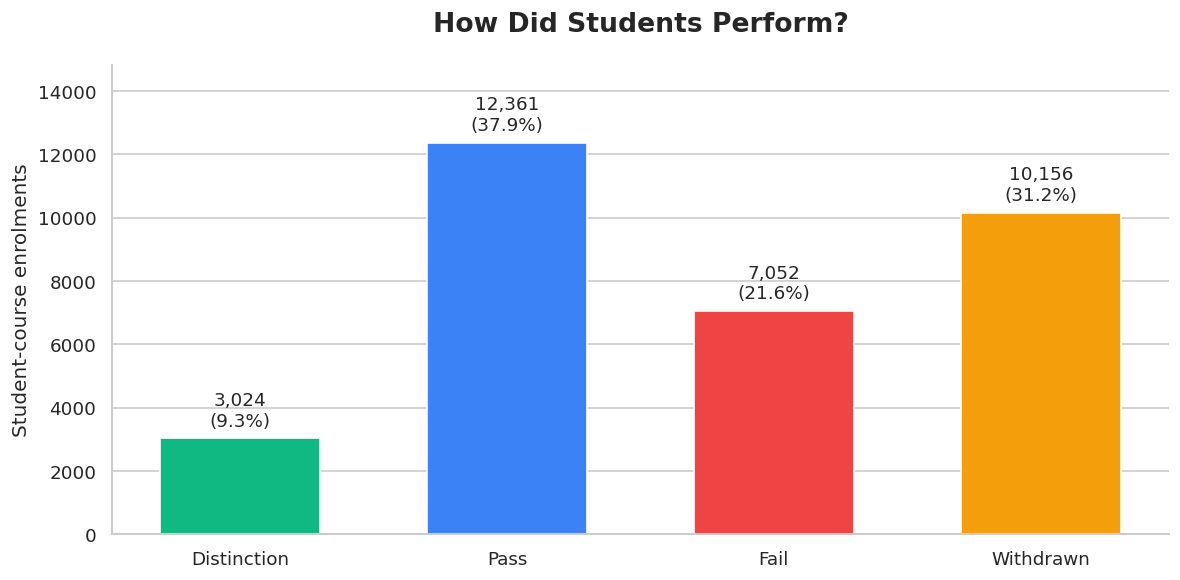

In [10]:
counts = merged["final_result"].value_counts().reindex(order, fill_value=0)

fig, ax = plt.subplots()

bars = ax.bar(
    counts.index,
    counts.values,
    color=[colors[result] for result in order],
    width=0.6
)

labels = [
    f"{count:,}\n({count / len(merged):.1%})"
    for count in counts
]

ax.bar_label(bars, labels=labels, padding=5, fontsize=11)

ax.set_title("How Did Students Perform?", pad=20)
ax.set_xlabel("")
ax.set_ylabel("Student-course enrolments")
ax.set_ylim(0, counts.max() * 1.2)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig("/kaggle/working/final_result_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

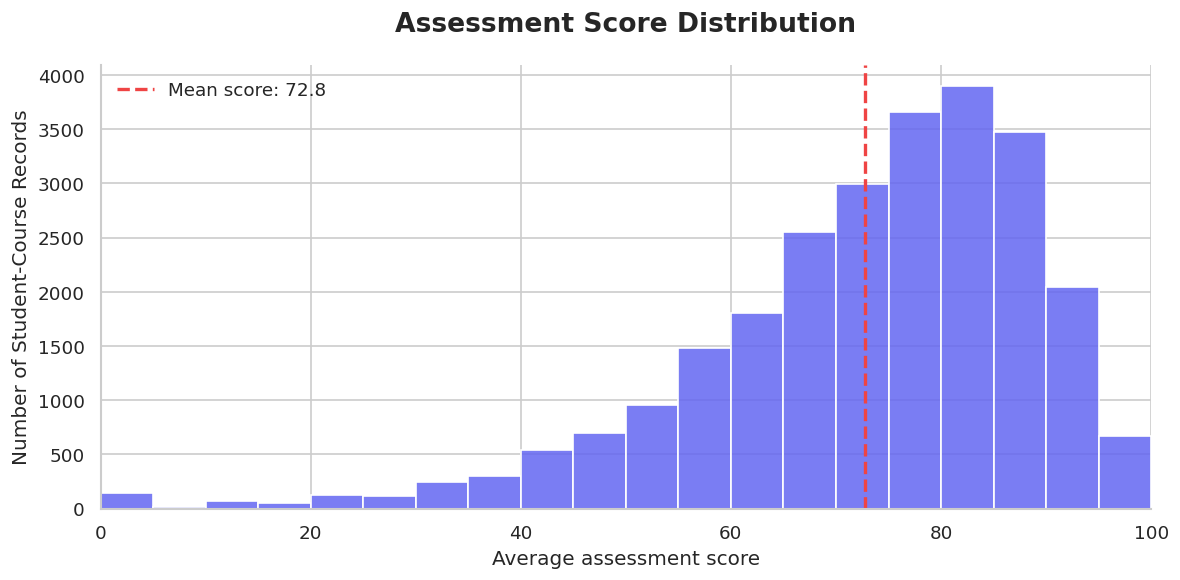

In [11]:
scores = merged["average_score"].dropna()
mean_score = scores.mean()

fig, ax = plt.subplots()

sns.histplot(
    scores,
    bins=20,
    binrange=(0, 100),
    color="#6366F1",
    edgecolor="white",
    alpha=0.85,
    ax=ax
)

ax.axvline(
    mean_score,
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label=f"Mean score: {mean_score:.1f}"
)

ax.set_title("Assessment Score Distribution", pad=20)
ax.set_xlabel("Average assessment score")
ax.set_ylabel("Number of Student-Course Records")
ax.set_xlim(0, 100)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("/kaggle/working/assessment_score_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

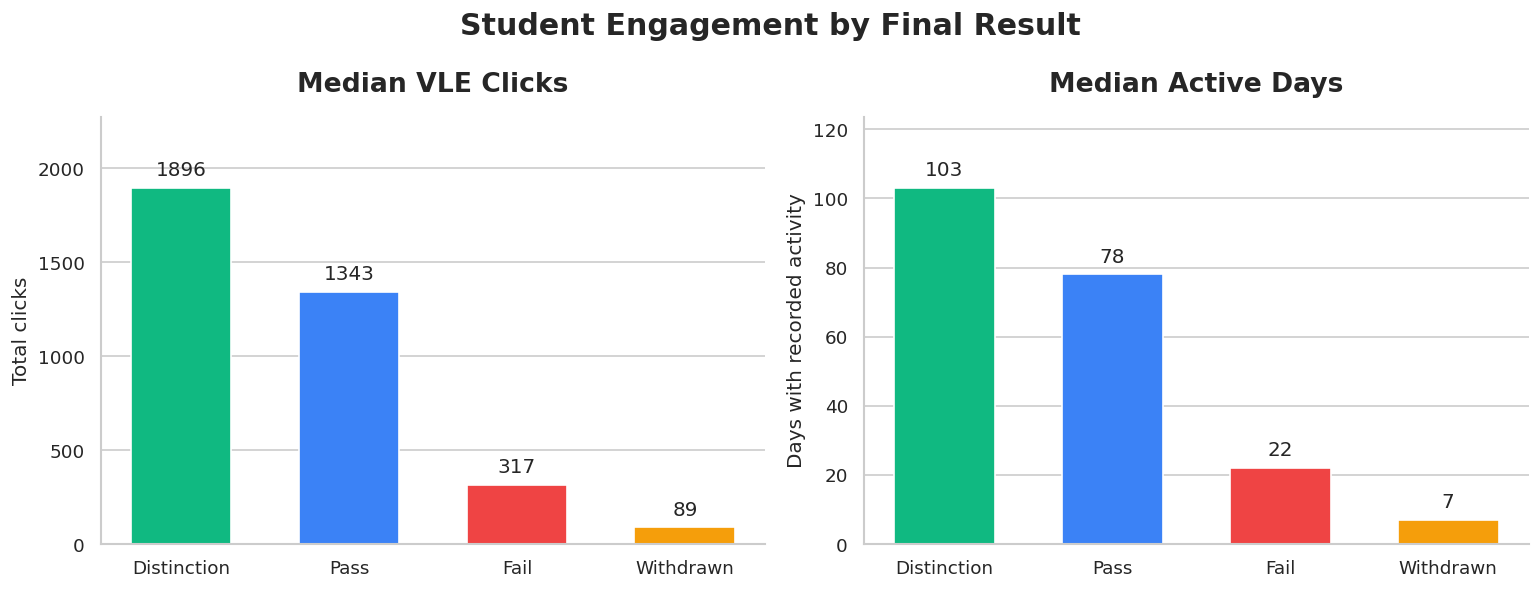

In [12]:
engagement_summary = (
    merged.groupby("final_result")[["total_clicks", "active_days"]]
    .median()
    .reindex(order)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title, ylabel in zip(
    axes,
    ["total_clicks", "active_days"],
    ["Median VLE Clicks", "Median Active Days"],
    ["Total clicks", "Days with recorded activity"]
):
    bars = ax.bar(
        order,
        engagement_summary[column],
        color=[colors[result] for result in order],
        width=0.6
    )

    ax.bar_label(bars, fmt="%.0f", padding=5)
    ax.set_title(title, pad=15)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, engagement_summary[column].max() * 1.2)
    ax.grid(axis="x", visible=False)

fig.suptitle("Student Engagement by Final Result", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/engagement_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

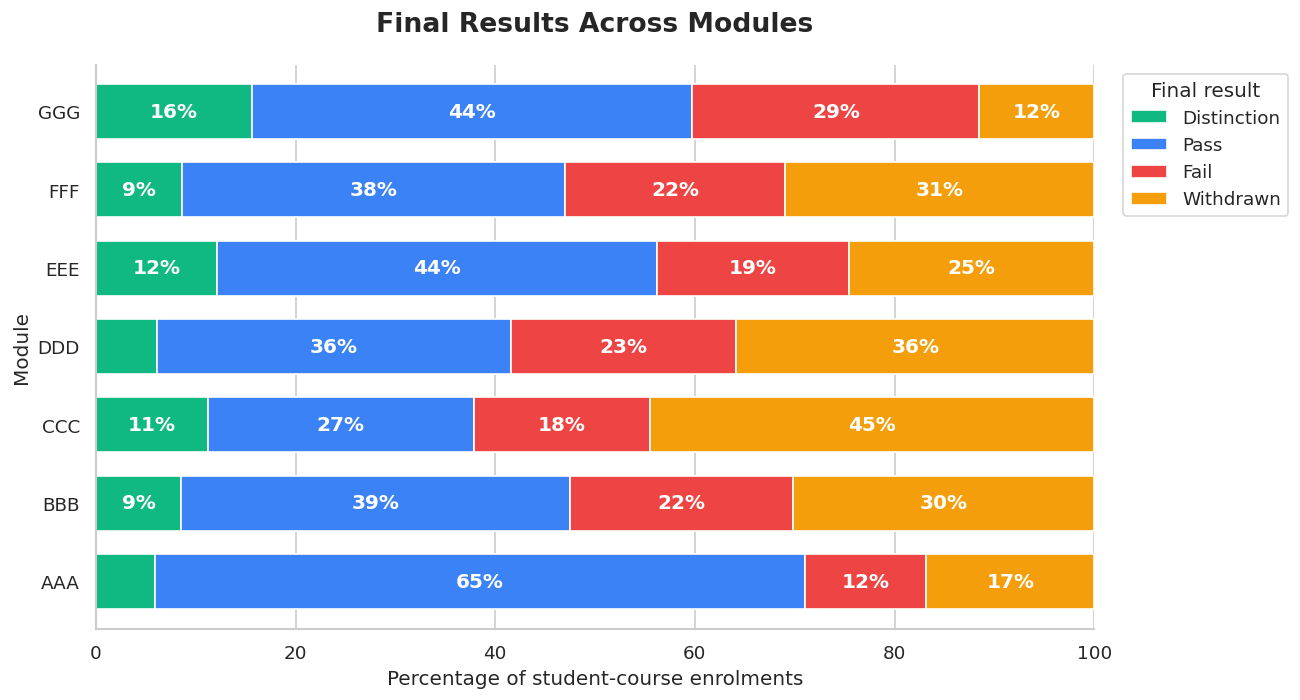

In [13]:
module_results = pd.crosstab(
    merged["code_module"],
    merged["final_result"],
    normalize="index"
).mul(100).reindex(columns=order, fill_value=0)

ax = module_results.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=[colors[result] for result in order],
    width=0.7
)

for container in ax.containers:
    labels = [
        f"{value:.0f}%" if value >= 7 else ""
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, label_type="center",
                 color="white", fontweight="bold")

ax.set_title("Final Results Across Modules", pad=20)
ax.set_xlabel("Percentage of student-course enrolments")
ax.set_ylabel("Module")
ax.set_xlim(0, 100)
ax.legend(title="Final result", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig("/kaggle/working/module_performance.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [14]:
merged.isna().sum()

code_module                       0
code_presentation                 0
id_student                        0
gender                            0
region                            0
highest_education                 0
imd_band                          0
age_band                          0
num_of_prev_attempts              0
studied_credits                   0
disability                        0
final_result                      0
date_registration                45
date_unregistration           22521
module_presentation_length        0
total_clicks                      0
active_days                       0
resources_accessed                0
clicks_per_active_day          3365
average_score                  6773
assessments_recorded              0
assessments_scored                0
dtype: int64

In [15]:
print(merged["average_score"].head(10))

0    82.0
1    66.4
2     NaN
3    76.0
4    54.4
5    68.0
6    68.0
7    72.4
8    71.4
9    78.0
Name: average_score, dtype: float64


| Column | Missing | Meaning and treatment |
|---|---:|---|
| `date_registration` | 45 | Registration date is unavailable. Keep missing. |
| `date_unregistration` | 22,521 | No unregistration date is recorded. Keep missing; zero would mean unregistration on day 0. |
| `clicks_per_active_day` | 3,365 | No recorded active days, so clicks per active day cannot be calculated. Keep missing. |
| `average_score` | 6,773 | No available assessment scores for these enrolments. Keep missing; zero would incorrectly represent a score of 0. |

### Remaining Missing Values

Missing values are retained where information is unavailable or a metric
cannot be calculated. Missing dates are not replaced with artificial
values. Enrolments without recorded activity have no clicks-per-active-day
value, while enrolments without available scores have no average score.
Count columns use zero to indicate no recorded activity or assessments.

## 8. Engagement and Assignment Submission Patterns Across Modules

The dataset does not contain department information or classroom
attendance records. Therefore, comparisons use course modules.

VLE active days describe online engagement rather than attendance.
Assignment submission rates measure the proportion of offered
non-exam assessments with a recorded, non-banked student submission.

**Compare active days across modules**

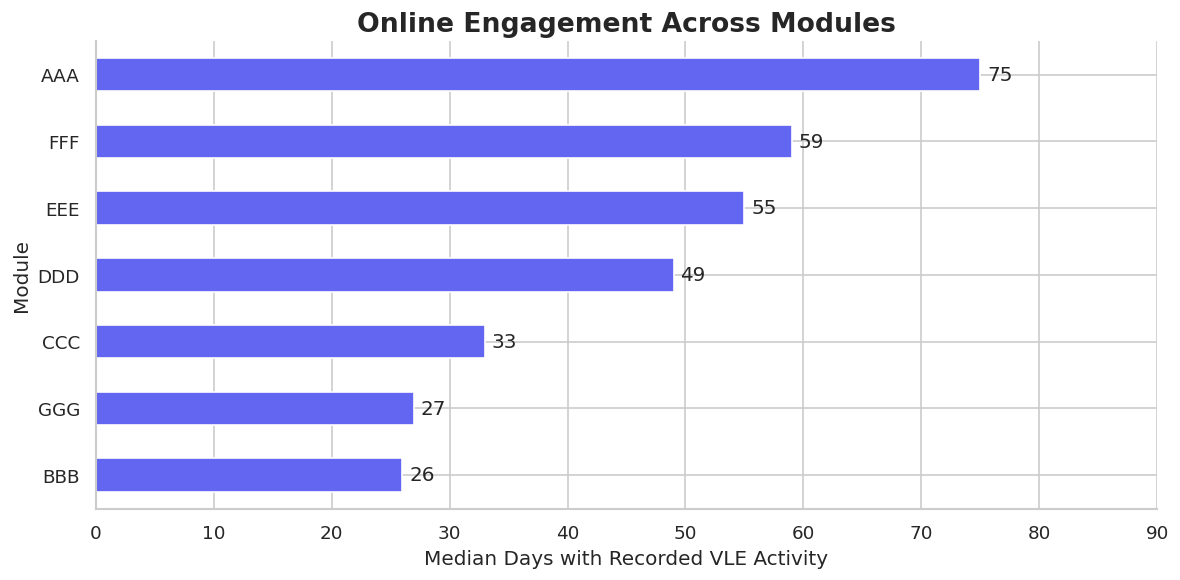

In [16]:
# Calculate median active days for each module
module_activity = (
    merged.groupby("code_module")["active_days"]
    .median()
    .sort_values()
)

ax = module_activity.plot(
    kind="barh",
    color="#6366F1",
    figsize=(10, 5)
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)

plt.title("Online Engagement Across Modules")
plt.xlabel("Median Days with Recorded VLE Activity")
plt.ylabel("Module")
plt.xlim(0, module_activity.max() * 1.2)
plt.tight_layout()
plt.show()

**Calculate assignment submission rates**
Count TMA and CMA assessments, excluding exams. Exclude banked records because they represent credit carried over from an earlier presentation.

In [17]:
# Select non-exam assignments
assignments = assessments[
    assessments["assessment_type"].isin(["TMA", "CMA"])
]

# Count assignments offered in each module and presentation
assignment_totals = (
    assignments.groupby(["code_module", "code_presentation"])
    ["id_assessment"]
    .nunique()
    .reset_index(name="assignments_offered")
)

# Keep recorded submissions for these assignments
assignment_records = student_assessment.merge(
    assignments[[
        "id_assessment", "code_module", "code_presentation"
    ]],
    on="id_assessment",
    how="inner",
    validate="many_to_one"
)

# Exclude credit carried over from previous study
assignment_records = assignment_records[
    assignment_records["is_banked"] == 0
]

# Count assignments submitted by each student
assignment_counts = (
    assignment_records.groupby(keys)["id_assessment"]
    .nunique()
    .reset_index(name="assignments_submitted")
)

# Create a separate table for this analysis
completion = merged[keys + ["final_result"]].copy()

completion = completion.merge(
    assignment_totals,
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)

completion = completion.merge(
    assignment_counts,
    on=keys,
    how="left",
    validate="one_to_one"
)

completion["assignments_submitted"] = (
    completion["assignments_submitted"].fillna(0).astype(int)
)

# Calculate the percentage of offered assignments submitted
completion["submission_rate"] = (
    completion["assignments_submitted"]
    / completion["assignments_offered"]
    * 100
).round(2)

display(completion.head())

,code_module,code_presentation,id_student,final_result,assignments_offered,assignments_submitted,submission_rate
0,AAA,2013J,11391,Pass,5,5,100.0
1,AAA,2013J,28400,Pass,5,5,100.0
2,AAA,2013J,30268,Withdrawn,5,0,0.0
3,AAA,2013J,31604,Pass,5,5,100.0
4,AAA,2013J,32885,Pass,5,5,100.0


Plot assignment submission patterns across modules

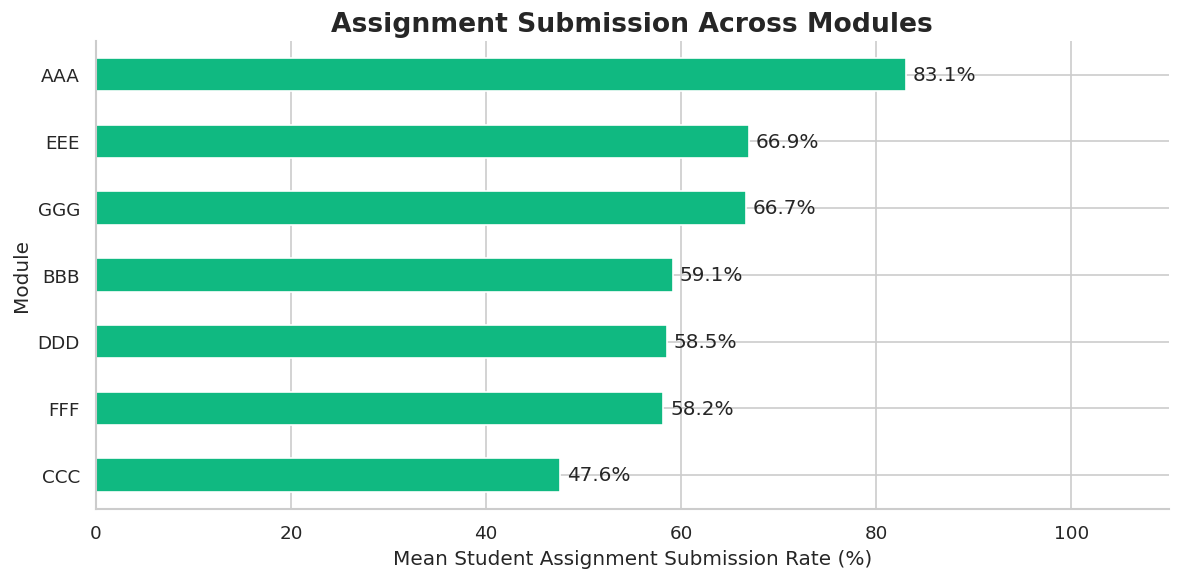

In [18]:
module_completion = (
    completion.groupby("code_module")["submission_rate"]
    .mean()
    .sort_values()
)

ax = module_completion.plot(
    kind="barh",
    color="#10B981",
    figsize=(10, 5)
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)

plt.title("Assignment Submission Across Modules")
plt.xlabel("Mean Student Assignment Submission Rate (%)")
plt.ylabel("Module")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

## Assessment Scores and Submission Timing

Explore individual assessment scores by assessment type, module,
and final outcome. Exclude banked records, which represent credit
carried over from earlier study.

Submission lateness is calculated as submission day minus the
scheduled assessment day.

In [19]:
# Exclude carried-over assessment records
assessment_eda = assessment_details[
    assessment_details["is_banked"] == 0
].copy()

# Add each student's final outcome
assessment_eda = assessment_eda.merge(
    merged[keys + ["final_result"]],
    on=keys,
    how="inner",
    validate="many_to_one"
)

# Positive = late; zero = on time; negative = early
assessment_eda["lateness_days"] = (
    assessment_eda["date_submitted"] - assessment_eda["date"]
)

# Keep available scores for score charts
scored = assessment_eda.dropna(subset=["score"])

**Score distributions by assessment type, module, and outcome**

Boxplots show the median, spread, and differences between groups. Each observation represents an assessment record, so students with more assessments contribute more observations.

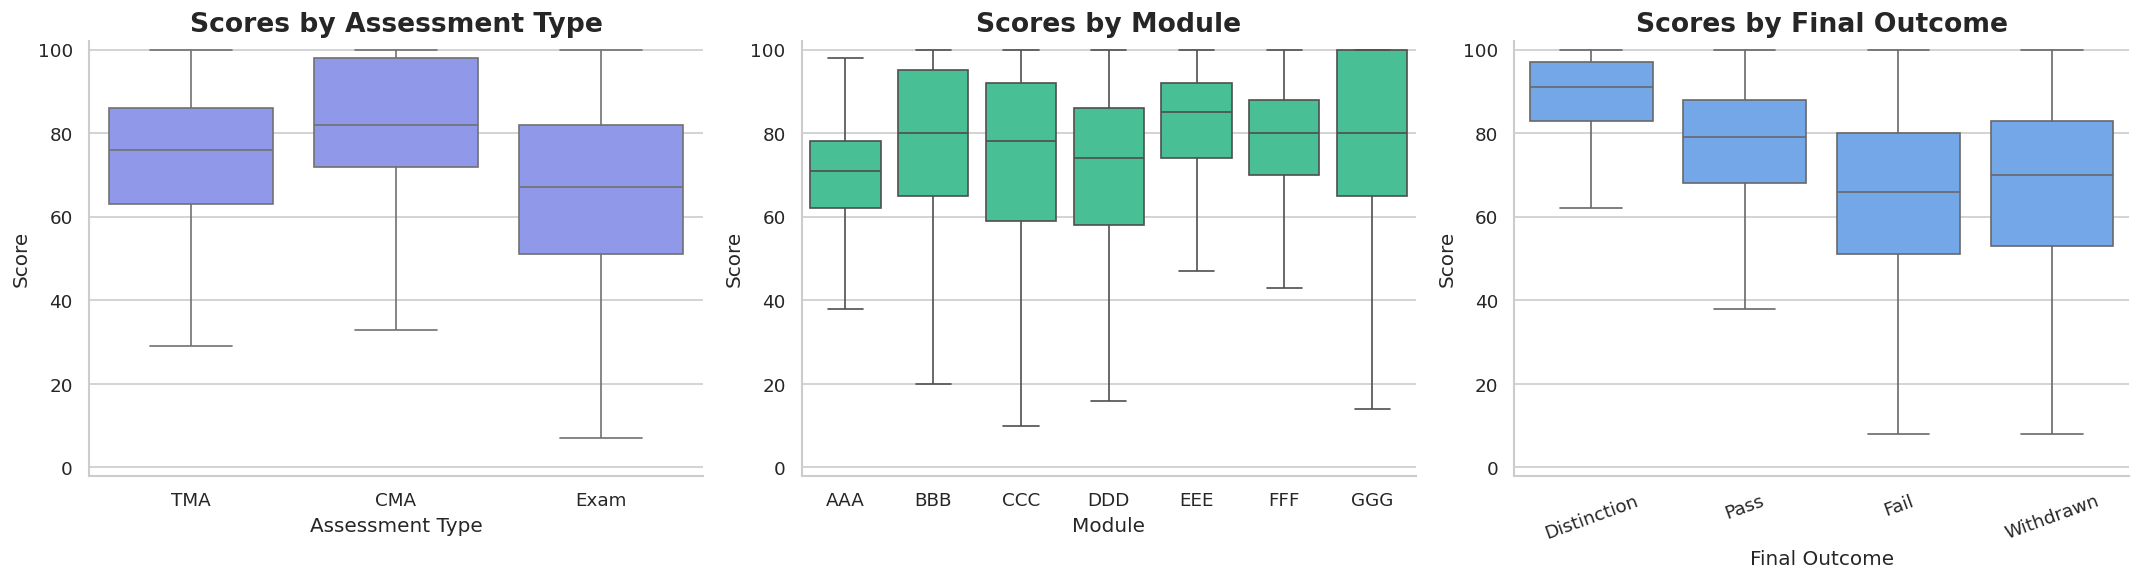

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scores by assessment type
sns.boxplot(
    data=scored,
    x="assessment_type",
    y="score",
    order=["TMA", "CMA", "Exam"],
    color="#818CF8",
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Scores by Assessment Type")
axes[0].set_xlabel("Assessment Type")
axes[0].set_ylabel("Score")

# Scores by module
sns.boxplot(
    data=scored,
    x="code_module",
    y="score",
    color="#34D399",
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("Scores by Module")
axes[1].set_xlabel("Module")
axes[1].set_ylabel("Score")

# Scores by final outcome
sns.boxplot(
    data=scored,
    x="final_result",
    y="score",
    order=order,
    color="#60A5FA",
    showfliers=False,
    ax=axes[2]
)

axes[2].set_title("Scores by Final Outcome")
axes[2].set_xlabel("Final Outcome")
axes[2].set_ylabel("Score")
axes[2].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.set_ylim(-2, 102)

plt.tight_layout()
plt.savefig("/kaggle/working/assessment_score_comparisons.png",
            dpi=300, bbox_inches="tight")
plt.show()

Submission lateness distribution

Use TMA and CMA records with known scheduled dates. Missing scores do not prevent a recorded submission from being included.

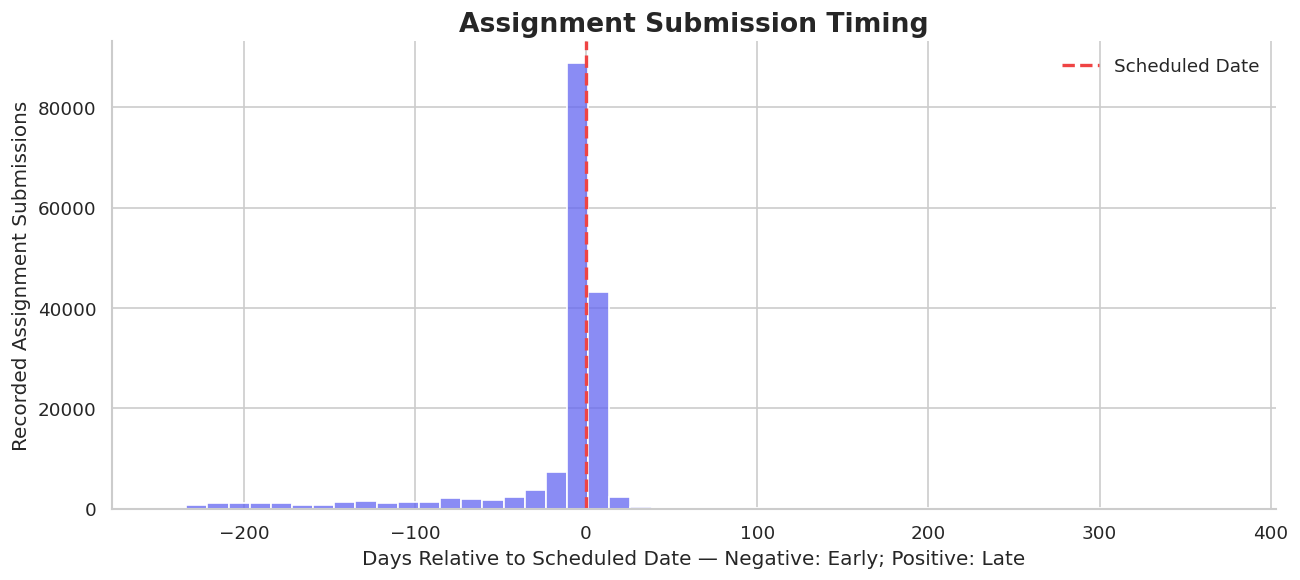

,Submissions,Percentage
Early,88264,52.8
On time,29469,17.6
Late,49311,29.5


In [21]:
# Select assignments with known submission and scheduled dates
timing = assessment_eda[
    assessment_eda["assessment_type"].isin(["TMA", "CMA"])
].dropna(subset=["lateness_days"])

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=timing,
    x="lateness_days",
    bins=50,
    color="#6366F1",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    0,
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label="Scheduled Date"
)

ax.set_title("Assignment Submission Timing")
ax.set_xlabel("Days Relative to Scheduled Date — Negative: Early; Positive: Late")
ax.set_ylabel("Recorded Assignment Submissions")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("/kaggle/working/submission_lateness.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Summarise early, on-time, and late submissions
timing_summary = pd.Series({
    "Early": (timing["lateness_days"] < 0).sum(),
    "On time": (timing["lateness_days"] == 0).sum(),
    "Late": (timing["lateness_days"] > 0).sum()
}).to_frame("Submissions")

timing_summary["Percentage"] = (
    timing_summary["Submissions"] / len(timing) * 100
).round(1)

display(timing_summary)

## Student Characteristics and Final Outcomes

Compare outcome percentages across deprivation bands, age groups,
education levels, and previous attempts.

Each observation represents a student-course enrolment.
These comparisons describe associations and do not establish causes.

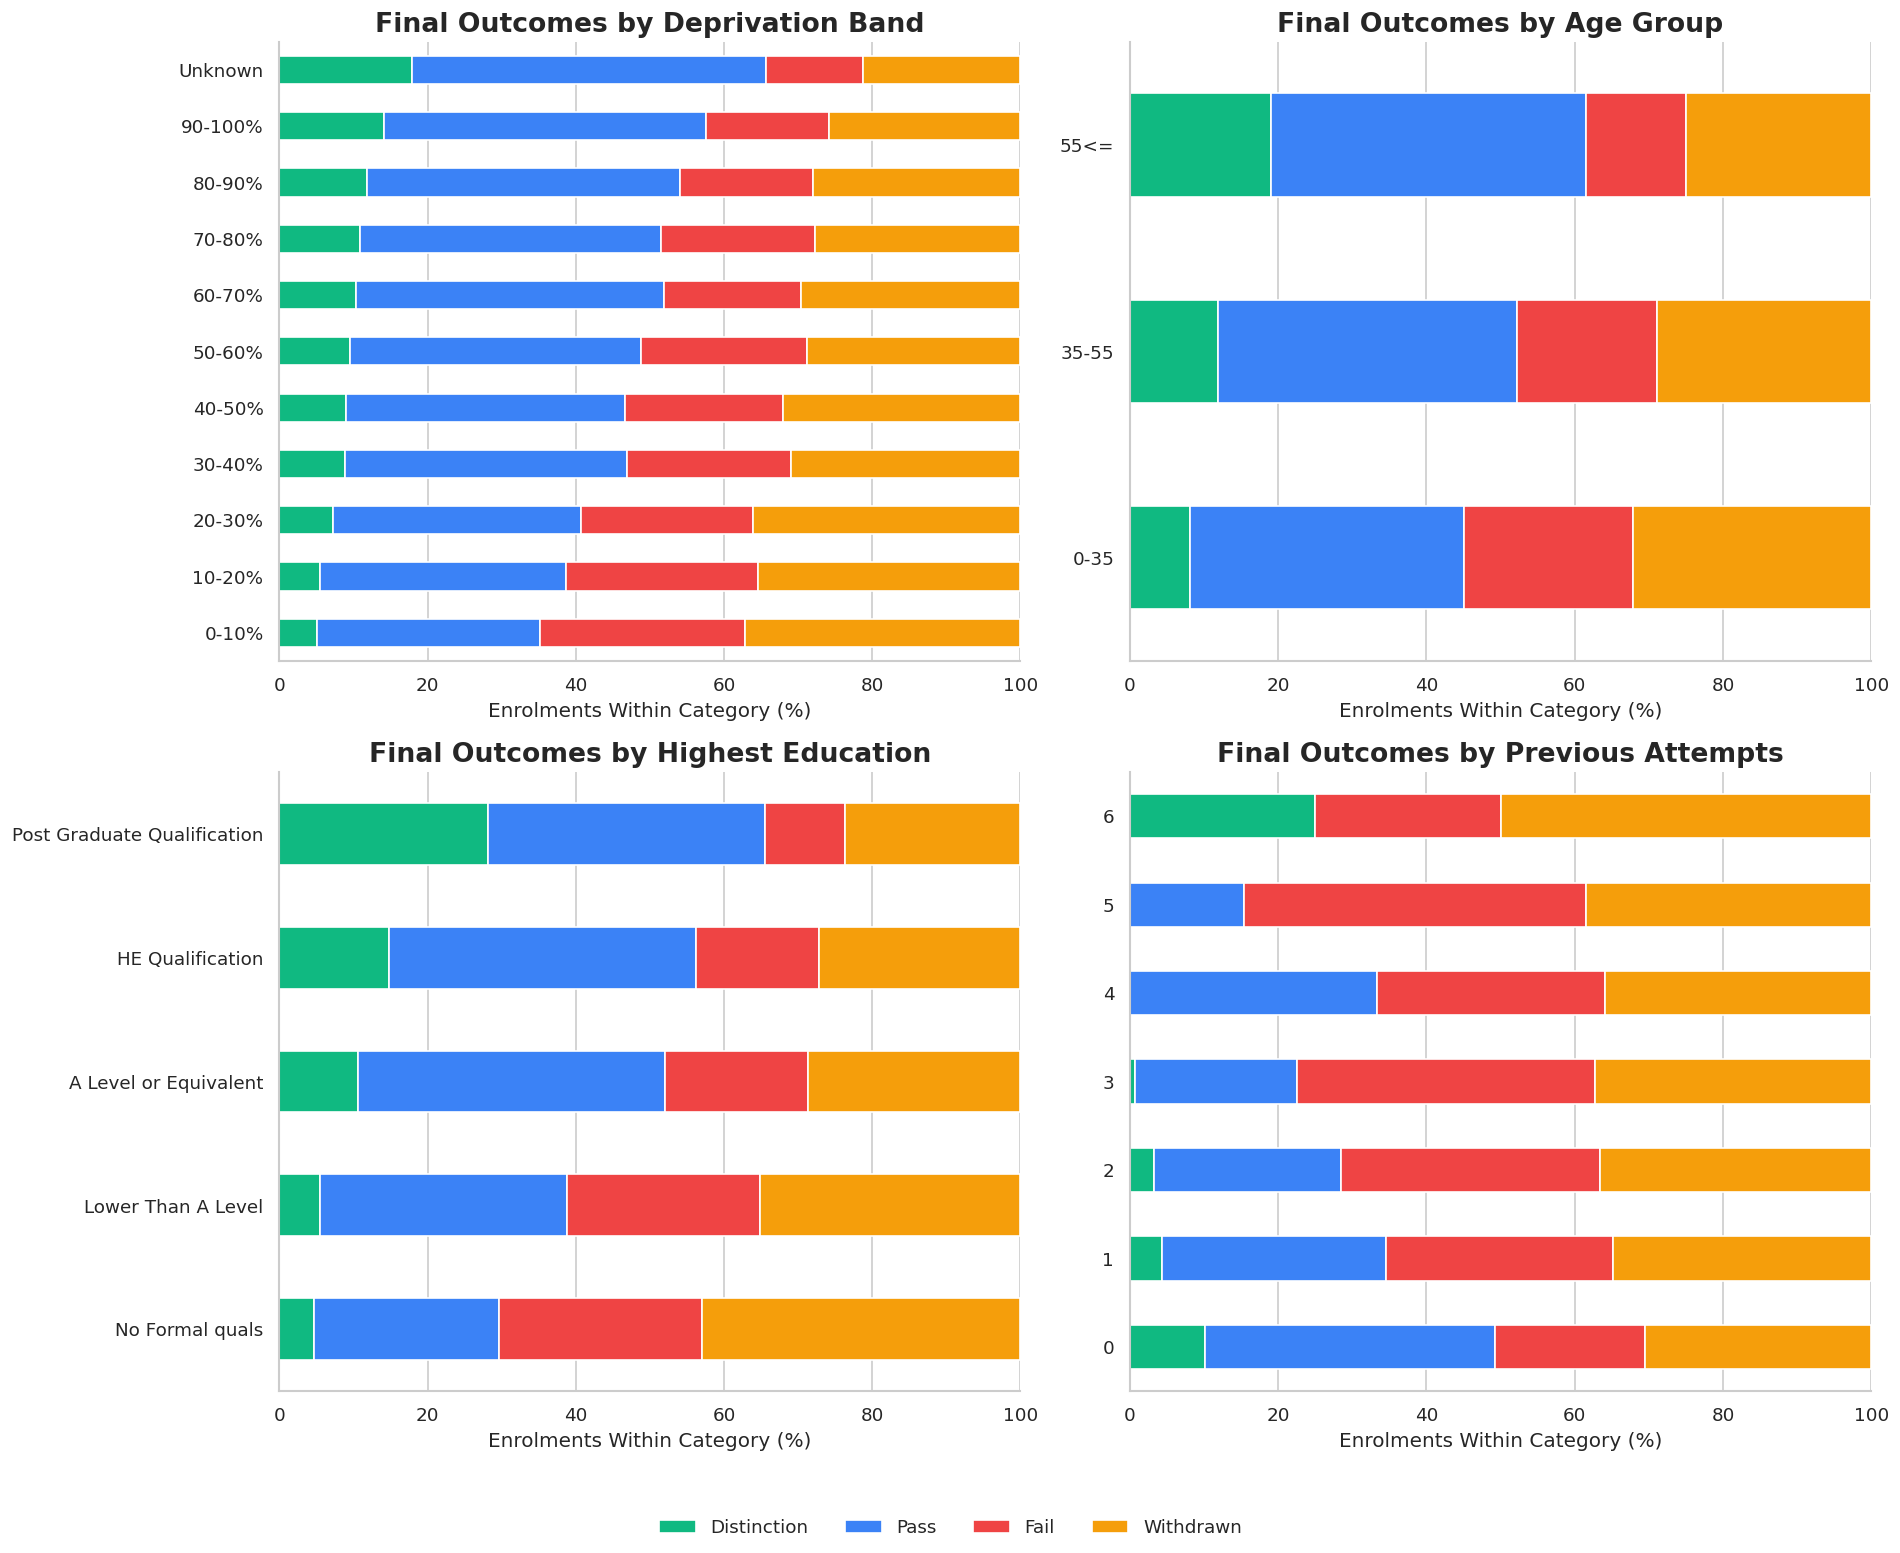

In [22]:
# Arrange demographic categories in a meaningful order
imd_order = [
    "0-10%", "10-20%", "20-30%", "30-40%", "40-50%",
    "50-60%", "60-70%", "70-80%", "80-90%", "90-100%",
    "Unknown"
]

age_order = ["0-35", "35-55", "55<="]

education_order = [
    "No Formal quals",
    "Lower Than A Level",
    "A Level or Equivalent",
    "HE Qualification",
    "Post Graduate Qualification"
]

demographics = [
    ("imd_band", "Deprivation Band", imd_order),
    ("age_band", "Age Group", age_order),
    ("highest_education", "Highest Education", education_order),
    (
        "num_of_prev_attempts",
        "Previous Attempts",
        sorted(merged["num_of_prev_attempts"].unique())
    )
]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

for ax, (column, title, category_order) in zip(
    axes.flat, demographics
):
    # Calculate outcome percentages within each category
    percentages = pd.crosstab(
        merged[column],
        merged["final_result"],
        normalize="index"
    ).mul(100)

    percentages = percentages.reindex(
        index=category_order,
        columns=order,
        fill_value=0
    )

    percentages.plot(
        kind="barh",
        stacked=True,
        color=[colors[result] for result in order],
        ax=ax,
        legend=False
    )

    ax.set_title(f"Final Outcomes by {title}")
    ax.set_xlabel("Enrolments Within Category (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)

# Add one shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("/kaggle/working/demographics_and_outcomes.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [23]:
for column, title, category_order in demographics:
    print(f"\n{title}: Enrolment Counts")

    display(
        merged[column]
        .value_counts()
        .reindex(category_order, fill_value=0)
        .to_frame("Enrolments")
    )


Deprivation Band: Enrolment Counts


,Enrolments
imd_band,
0-10%,3311
10-20%,3516
20-30%,3654
30-40%,3539
40-50%,3256
50-60%,3124
60-70%,2905
70-80%,2879
80-90%,2762



Age Group: Enrolment Counts


,Enrolments
age_band,
0-35,22944
35-55,9433
55<=,216



Highest Education: Enrolment Counts


,Enrolments
highest_education,
No Formal quals,347
Lower Than A Level,13158
A Level or Equivalent,14045
HE Qualification,4730
Post Graduate Qualification,313



Previous Attempts: Enrolment Counts


,Enrolments
num_of_prev_attempts,
0,28421
1,3299
2,675
3,142
4,39
5,13
6,4


In [24]:
from IPython.display import Markdown, display

# Final result distribution
result_counts = merged["final_result"].value_counts()
largest_result = result_counts.idxmax()
largest_percentage = result_counts.max() / len(merged) * 100

# Assessment scores
available_scores = merged["average_score"].dropna()

# Engagement by final result
engagement_medians = (
    merged.groupby("final_result")[["total_clicks", "active_days"]]
    .median()
)

highest_clicks = engagement_medians["total_clicks"].idxmax()
highest_days = engagement_medians["active_days"].idxmax()

# Final results across modules
module_results = pd.crosstab(
    merged["code_module"],
    merged["final_result"],
    normalize="index"
).mul(100)

# Combine Pass and Distinction as successful outcomes
module_success = module_results[["Pass", "Distinction"]].sum(axis=1)
highest_success = module_success.idxmax()

findings = f"""
## Key Findings

### 1. Final Result Distribution
**{largest_result}** is the largest outcome group, accounting for
**{result_counts.max():,} enrolments ({largest_percentage:.1f}%)**.

### 2. Assessment Score Distribution
Among enrolments with available scores, the mean student-level average
score is **{available_scores.mean():.2f}/100**, and the median is
**{available_scores.median():.2f}/100**.
**{merged["average_score"].isna().sum():,} enrolments** have no available
average score and are excluded from this distribution.

### 3. Engagement by Final Result
The **{highest_clicks}** group has the highest median total clicks
(**{engagement_medians.loc[highest_clicks, "total_clicks"]:,.0f}**).
The **{highest_days}** group has the highest median active days
(**{engagement_medians.loc[highest_days, "active_days"]:.0f} days**).

These are associations between recorded engagement and outcomes;
they do not establish causation.

### 4. Final Results Across Modules
Module **{highest_success}** has the highest combined percentage of
Pass and Distinction outcomes (**{module_success.max():.1f}%**).
These comparisons pool presentations within each module.
"""

display(Markdown(findings))


## Key Findings

### 1. Final Result Distribution
**Pass** is the largest outcome group, accounting for
**12,361 enrolments (37.9%)**.

### 2. Assessment Score Distribution
Among enrolments with available scores, the mean student-level average
score is **72.77/100**, and the median is
**76.00/100**.
**6,773 enrolments** have no available
average score and are excluded from this distribution.

### 3. Engagement by Final Result
The **Distinction** group has the highest median total clicks
(**1,896**).
The **Distinction** group has the highest median active days
(**103 days**).

These are associations between recorded engagement and outcomes;
they do not establish causation.

### 4. Final Results Across Modules
Module **AAA** has the highest combined percentage of
Pass and Distinction outcomes (**71.0%**).
These comparisons pool presentations within each module.


## Define the Prediction Target and Features

The target identifies an unsuccessful final outcome:
- 1: Fail or Withdrawn
- 0: Pass or Distinction

The initial model uses student and course information available at
enrolment. Full-course engagement, assessment summaries, and
unregistration dates are excluded because they contain information
from after the prediction point.

In [25]:
# Work on a separate copy for modelling
model_data = merged.copy()

# Define the target from the final outcome
model_data["risk"] = model_data["final_result"].map({
    "Fail": 1,
    "Withdrawn": 1,
    "Pass": 0,
    "Distinction": 0
})

# Check that every outcome was mapped
assert model_data["risk"].notna().all()

model_data["risk"] = model_data["risk"].astype(int)

# Select baseline features available at enrolment
feature_columns = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability",
    "module_presentation_length"
]

# Inputs and target
X = model_data[feature_columns].copy()
y = model_data["risk"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (32593, 11)
Target shape: (32593,)


,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,module_presentation_length
0,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,268
1,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,268
2,AAA,2013J,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,268
3,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,268
4,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,268


In [26]:
target_summary = (
    y.value_counts()
    .reindex([0, 1], fill_value=0)
    .to_frame("Enrolments")
)

target_summary["Percentage"] = (
    target_summary["Enrolments"] / len(y) * 100
).round(2)

target_summary.index = ["Successful (0)", "At risk (1)"]

display(target_summary)

,Enrolments,Percentage
Successful (0),15385,47.2
At risk (1),17208,52.8


#  Retention Funnel Analysis

In [27]:
# Identify a student within a specific module presentation.
KEY = ["code_module", "code_presentation", "id_student"]

GROUP_KEYS = ["code_module", "code_presentation"]

DAY30 = 30

print("Student keys and analysis settings defined.")

Student keys and analysis settings defined.


In [28]:

# Create one internal record per student, module and presentation.
funnel = registration[
    KEY + ["date_registration", "date_unregistration"]
].drop_duplicates(subset=KEY).copy()

results = student_info[
    KEY + ["final_result"]
].drop_duplicates()

funnel = funnel.merge(
    results,
    on=KEY,
    how="left",
    validate="one_to_one"
)

assert not funnel.duplicated(KEY).any(), (
    "Duplicate student-module-presentation records found."
)

print("Base retention dataset created.")
print("Registered records:", len(funnel))
print("Duplicate student records:", int(funnel.duplicated(KEY).sum()))


Base retention dataset created.
Registered records: 32593
Duplicate student records: 0


In [29]:

# Identify students who had not withdrawn by Day 30.
funnel["Day30_Eligible"] = (
    funnel["date_unregistration"].isna()
    | (funnel["date_unregistration"] > DAY30)
).astype(int)

day30_summary = (
    funnel.groupby(GROUP_KEYS)
    .agg(
        registered_students=("Day30_Eligible", "size"),
        day30_eligible_students=("Day30_Eligible", "sum")
    )
    .reset_index()
)

print("Registered records:", len(funnel))
print(
    "Day 30 eligible records:",
    int(funnel["Day30_Eligible"].sum())
)
print(
    "Withdrawn by Day 30:",
    int((funnel["Day30_Eligible"] == 0).sum())
)


Registered records: 32593
Day 30 eligible records: 27466
Withdrawn by Day 30: 5127


In [30]:
# Identify VLE activity during Days 0–30 for Day 30 eligible students.
eligible_keys = funnel.loc[
    funnel["Day30_Eligible"] == 1,
    KEY
]

early_activity = student_vle.loc[
    student_vle["date"].between(0, DAY30)
    & (student_vle["sum_click"] > 0),
    KEY
].drop_duplicates()

# Keep activity records belonging to the Day 30 eligible population.
early_activity = early_activity.merge(
    eligible_keys,
    on=KEY,
    how="inner",
    validate="one_to_one"
)

early_activity["Active_First_30_Days"] = 1

funnel = funnel.merge(
    early_activity,
    on=KEY,
    how="left",
    validate="one_to_one"
)

funnel["Active_First_30_Days"] = (
    funnel["Active_First_30_Days"]
    .fillna(0)
    .astype(int)
)

print(
    "Day 30 eligible students active during Days 0–30:",
    int(funnel["Active_First_30_Days"].sum())
)

Day 30 eligible students active during Days 0–30: 26322


In [31]:

# Find the earliest scheduled assessment date per module presentation.
valid_assessments = assessments.dropna(subset=["date"]).copy()

first_assessment_dates = (
    valid_assessments.groupby(GROUP_KEYS, as_index=False)["date"]
    .min()
    .rename(columns={"date": "first_assessment_date"})
)

first_assessment = valid_assessments.merge(
    first_assessment_dates,
    left_on=GROUP_KEYS + ["date"],
    right_on=GROUP_KEYS + ["first_assessment_date"],
    how="inner",
    validate="many_to_one"
)[GROUP_KEYS + ["id_assessment"]].drop_duplicates()

print(
    "Module-presentation groups with a scheduled first assessment:",
    len(first_assessment_dates)
)


Module-presentation groups with a scheduled first assessment: 22


In [32]:

# Identify students eligible at Day 30.
eligible_keys = funnel.loc[
    funnel["Day30_Eligible"] == 1,
    KEY
]

# Match submissions to the first scheduled assessment.
assessment_submissions = student_assessment.merge(
    first_assessment,
    on="id_assessment",
    how="inner",
    validate="many_to_many"
)

# Keep submissions made during Days 0–30.
first_submissions = assessment_submissions.loc[
    assessment_submissions["date_submitted"].between(
        0, DAY30, inclusive="both"
    ),
    KEY
].drop_duplicates()

# Include only students eligible at Day 30.
first_submissions = first_submissions.merge(
    eligible_keys,
    on=KEY,
    how="inner",
    validate="one_to_one"
)

first_submissions["Submitted_First_Assessment"] = 1

# Merge the submission indicator into the funnel.
funnel = funnel.merge(
    first_submissions,
    on=KEY,
    how="left",
    validate="one_to_one"
)

funnel["Submitted_First_Assessment"] = (
    funnel["Submitted_First_Assessment"]
    .fillna(0)
    .astype(int)
)

print(
    "Day 30 eligible students who submitted the first "
    "scheduled assessment:",
    int(funnel["Submitted_First_Assessment"].sum())
)


Day 30 eligible students who submitted the first scheduled assessment: 20214


In [33]:

# Determine whether each student remained registered at the module midpoint.
funnel = funnel.merge(
    courses[
        GROUP_KEYS + ["module_presentation_length"]
    ].drop_duplicates(),
    on=GROUP_KEYS,
    how="left",
    validate="many_to_one"
)

funnel["midpoint"] = (
    funnel["module_presentation_length"] // 2
)

funnel["Still_Registered_Mid_Module"] = (
    funnel["date_registration"].notna()
    & (funnel["date_registration"] <= funnel["midpoint"])
    & (
        funnel["date_unregistration"].isna()
        | (funnel["date_unregistration"] > funnel["midpoint"])
    )
).astype(int)

print(
    "Students registered at the module midpoint:",
    int(funnel["Still_Registered_Mid_Module"].sum())
)


Students registered at the module midpoint: 24592


In [34]:

# Count students who completed the module.
funnel["Completed_Module"] = (
    funnel["final_result"].isin(["Pass", "Distinction", "Fail"])
).astype(int)

# Count only students whose final result is exactly Pass.
funnel["Passed"] = (
    funnel["final_result"].eq("Pass")
).astype(int)

print("Completed students:", int(funnel["Completed_Module"].sum()))
print("Students with final result Pass:", int(funnel["Passed"].sum()))


Completed students: 22437
Students with final result Pass: 12361


In [35]:

# Keep each stage independent; do not chain stages together.
# This allows students to be counted in an outcome stage even if
# they did not satisfy an earlier engagement stage.

funnel["Stage_Registered"] = 1

funnel["Stage_Day30_Eligible"] = (
    funnel["Day30_Eligible"]
)

funnel["Stage_Active_First_30_Days"] = (
    funnel["Active_First_30_Days"]
)

funnel["Stage_First_Assessment_Submitted"] = (
    funnel["Submitted_First_Assessment"]
)

funnel["Stage_Still_Registered_Mid_Module"] = (
    funnel["Still_Registered_Mid_Module"]
)

funnel["Stage_Completed_Module"] = (
    funnel["Completed_Module"]
)

funnel["Stage_Passed"] = (
    funnel["Passed"]
)

print("Independent retention stages created.")


Independent retention stages created.


In [36]:
# Aggregate counts only; do not display individual student records.
funnel_counts = (
    funnel.groupby(GROUP_KEYS)
    .agg(
        registered_students=("Stage_Registered", "sum"),
        day30_eligible_students=("Stage_Day30_Eligible", "sum"),
        active_first_30_days=("Stage_Active_First_30_Days", "sum"),
        first_assessment_submitted=("Stage_First_Assessment_Submitted", "sum"),
        still_registered_mid_module=("Stage_Still_Registered_Mid_Module", "sum"),
        completed_students=("Stage_Completed_Module", "sum"),
        passed_students=("Stage_Passed", "sum")
    )
    .reset_index()
)

print("Module-presentation groups:", len(funnel_counts))
print(
    "Total registered:",
    int(funnel_counts["registered_students"].sum())
)
print(
    "Total Day 30 eligible:",
    int(funnel_counts["day30_eligible_students"].sum())
)

display(funnel_counts.head(10))



Module-presentation groups: 22
Total registered: 32593
Total Day 30 eligible: 27466


,code_module,code_presentation,registered_students,day30_eligible_students,active_first_30_days,first_assessment_submitted,still_registered_mid_module,completed_students,passed_students
0,AAA,2013J,383,369,367,349,349,323,258
1,AAA,2014J,365,348,347,311,328,299,229
2,BBB,2013B,1767,1526,1434,1300,1380,1262,648
3,BBB,2013J,2237,1826,1695,1598,1677,1593,896
4,BBB,2014B,1613,1281,1200,1125,1191,1123,561
5,BBB,2014J,2292,1786,1725,1646,1664,1543,972
6,CCC,2014B,1936,1489,1450,1283,1219,1038,471
7,CCC,2014J,2498,2014,1975,1781,1644,1421,709
8,DDD,2013B,1303,1139,1103,977,997,871,456
9,DDD,2013J,1938,1636,1600,1358,1425,1257,731


In [37]:

# Independently count students whose final result is exactly Pass.
actual_pass_counts = (
    funnel.assign(
        actual_pass=funnel["final_result"].eq("Pass").astype(int)
    )
    .groupby(GROUP_KEYS, as_index=False)
    .agg(actual_pass_count=("actual_pass", "sum"))
)

# Compare the independent count with the Passed stage.
funnel_counts = funnel_counts.merge(
    actual_pass_counts,
    on=GROUP_KEYS,
    how="left",
    validate="one_to_one"
)

# Confirm there is only one row per module and presentation.
duplicate_groups = funnel_counts.duplicated(GROUP_KEYS).sum()

assert duplicate_groups == 0, (
    "Duplicate module-presentation rows found."
)

# Validate that Passed counts match final_result == Pass.
assert (
    funnel_counts["passed_students"]
    == funnel_counts["actual_pass_count"]
).all(), (
    "Passed counts do not match final_result == Pass."
)

print("Duplicate module-presentation rows:", int(duplicate_groups))
print("Passed-stage validation: PASSED")
print("Groups checked:", len(funnel_counts))

# Display aggregate counts only.
display(funnel_counts.head(10))


Duplicate module-presentation rows: 0
Passed-stage validation: PASSED
Groups checked: 22


,code_module,code_presentation,registered_students,day30_eligible_students,active_first_30_days,first_assessment_submitted,still_registered_mid_module,completed_students,passed_students,actual_pass_count
0,AAA,2013J,383,369,367,349,349,323,258,258
1,AAA,2014J,365,348,347,311,328,299,229,229
2,BBB,2013B,1767,1526,1434,1300,1380,1262,648,648
3,BBB,2013J,2237,1826,1695,1598,1677,1593,896,896
4,BBB,2014B,1613,1281,1200,1125,1191,1123,561,561
5,BBB,2014J,2292,1786,1725,1646,1664,1543,972,972
6,CCC,2014B,1936,1489,1450,1283,1219,1038,471,471
7,CCC,2014J,2498,2014,1975,1781,1644,1421,709,709
8,DDD,2013B,1303,1139,1103,977,997,871,456,456
9,DDD,2013J,1938,1636,1600,1358,1425,1257,731,731


In [38]:

from pathlib import Path
import pandas as pd

# Convert the module-presentation counts into the app's
# proposed two-column retention funnel format.
stage_columns = {
    "Registered": "registered_students",
    "Eligible at Day 30": "day30_eligible_students",
    "Active in First 30 Days": "active_first_30_days",
    "Submitted First Assessment": "first_assessment_submitted",
    "Registered at Midpoint": "still_registered_mid_module",
    "Completed Module": "completed_students",
    "Passed": "passed_students",
}

# Validate Passed counts against actual final results.
assert (
    funnel_counts["passed_students"]
    == funnel_counts["actual_pass_count"]
).all(), "Passed-stage validation failed."

# Aggregate across module-presentation groups to get stage totals.
funnel_rows = []

for stage, source_column in stage_columns.items():
    funnel_rows.append({
        "stage": stage,
        "students": int(funnel_counts[source_column].sum())
    })

retention_funnel = pd.DataFrame(
    funnel_rows,
    columns=["stage", "students"]
)

# Save aggregated output only.
output_path = Path("data/processed/retention_funnel.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
retention_funnel.to_csv(output_path, index=False)

# Verify the saved schema and privacy requirements.
saved_funnel = pd.read_csv(output_path)

assert list(saved_funnel.columns) == ["stage", "students"]
assert "id_student" not in saved_funnel.columns
assert saved_funnel["stage"].is_unique

print("Retention funnel saved successfully.")
print("Output path:", output_path)
print("Number of stages:", len(saved_funnel))
print("Student ID column present:", "id_student" in saved_funnel.columns)
print("Passed-stage validation: PASSED")
display(saved_funnel)


Retention funnel saved successfully.
Output path: data/processed/retention_funnel.csv
Number of stages: 7
Student ID column present: False
Passed-stage validation: PASSED


,stage,students
0,Registered,32593
1,Eligible at Day 30,27466
2,Active in First 30 Days,26322
3,Submitted First Assessment,20214
4,Registered at Midpoint,24592
5,Completed Module,22437
6,Passed,12361


# Department risk dashboard charts

In [39]:

import pandas as pd

DAY30 = 30
risk_results = ["Fail", "Withdrawn"]

# Create a copy so the original merged data remains unchanged.
risk_base = merged.copy()

# Define students who are at risk based on their final result.
risk_base["at_risk"] = (
    risk_base["final_result"].isin(risk_results).astype(int)
)

# Define students who withdrew.
risk_base["dropout"] = (
    risk_base["final_result"].eq("Withdrawn").astype(int)
)

# Identify students still active at Day 30.
# Students who withdrew on or before Day 30 are excluded.
risk_base["day30_eligible"] = (
    risk_base["date_unregistration"].isna()
    | (risk_base["date_unregistration"] > DAY30)
)

# Count at-risk and dropout students within the Day 30 population.
risk_base["day30_at_risk"] = (
    risk_base["at_risk"] * risk_base["day30_eligible"].astype(int)
)

risk_base["day30_dropout"] = (
    risk_base["dropout"] * risk_base["day30_eligible"].astype(int)
)

# Aggregate counts by module and presentation.
risk_summary = (
    risk_base.groupby(["code_module", "code_presentation"])
    .agg(
        registered_students=("id_student", "nunique"),
        at_risk_students=("at_risk", "sum"),
        dropout_students=("dropout", "sum"),
        day30_eligible_students=("day30_eligible", "sum"),
        day30_at_risk_students=("day30_at_risk", "sum"),
        day30_dropout_students=("day30_dropout", "sum")
    )
    .reset_index()
)

# Overall rates: include students who left before Day 30.
risk_summary["at_risk_rate"] = (
    risk_summary["at_risk_students"]
    / risk_summary["registered_students"].replace(0, float("nan"))
    * 100
)

risk_summary["dropout_rate"] = (
    risk_summary["dropout_students"]
    / risk_summary["registered_students"].replace(0, float("nan"))
    * 100
)

# Day 30 rates: use only students eligible at Day 30.
risk_summary["day30_at_risk_rate"] = (
    risk_summary["day30_at_risk_students"]
    / risk_summary["day30_eligible_students"].replace(0, float("nan"))
    * 100
)

risk_summary["day30_dropout_rate"] = (
    risk_summary["day30_dropout_students"]
    / risk_summary["day30_eligible_students"].replace(0, float("nan"))
    * 100
)

print("Risk summary created.")
print("Module-presentation groups:", len(risk_summary))
print("Overall at-risk rate includes early leavers.")
print("Day 30 at-risk rate excludes students who left on or before Day 30.")

display(risk_summary.head(10))


Risk summary created.
Module-presentation groups: 22
Overall at-risk rate includes early leavers.
Day 30 at-risk rate excludes students who left on or before Day 30.


,code_module,code_presentation,registered_students,at_risk_students,dropout_students,day30_eligible_students,day30_at_risk_students,day30_dropout_students,at_risk_rate,dropout_rate,day30_at_risk_rate,day30_dropout_rate
0,AAA,2013J,383,105,60,369,91,46,27.415144,15.665796,24.661247,12.466125
1,AAA,2014J,365,112,66,348,95,49,30.684932,18.082192,27.298851,14.080460
2,BBB,2013B,1767,964,505,1526,723,264,54.555744,28.579513,47.378768,17.300131
3,BBB,2013J,2237,1165,644,1826,754,235,52.078677,28.788556,41.292442,12.869660
4,BBB,2014B,1613,886,490,1281,554,158,54.928704,30.378177,43.247463,12.334114
5,BBB,2014J,2292,1140,749,1786,634,243,49.738220,32.678883,35.498320,13.605823
6,CCC,2014B,1936,1273,898,1489,826,451,65.754132,46.384298,55.473472,30.288784
7,CCC,2014J,2498,1483,1077,2014,999,593,59.367494,43.114492,49.602781,29.443893
8,DDD,2013B,1303,793,432,1139,629,268,60.859555,33.154259,55.223881,23.529412
9,DDD,2013J,1938,1109,681,1636,807,382,57.223942,35.139319,49.327628,23.349633


In [40]:

import plotly.express as px


def plot_risk_bar(data, metric, title, y_label):
    """Create and return a grouped bar chart."""
    fig = px.bar(
        data,
        x="code_module",
        y=metric,
        color="code_presentation",
        barmode="group",
        text_auto=".1f",
        title=title,
        labels={
            "code_module": "Module",
            "code_presentation": "Presentation",
            metric: y_label
        }
    )

    fig.update_layout(
        xaxis_title="Module",
        yaxis_title=y_label,
        legend_title="Presentation",
        template="plotly_white"
    )

    return fig


def plot_risk_heatmap(data, metric, title):
    """Create and return a module-versus-presentation heatmap."""
    heatmap_data = data.pivot(
        index="code_module",
        columns="code_presentation",
        values=metric
    )

    fig = px.imshow(
        heatmap_data,
        text_auto=".1f",
        aspect="auto",
        color_continuous_scale="Reds",
        title=title,
        labels={
            "x": "Presentation",
            "y": "Module",
            "color": "Percentage"
        }
    )

    fig.update_layout(template="plotly_white")

    return fig


In [41]:

# At-risk student count by module and presentation.
# Counts include students who withdrew before Day 30.

fig = plot_risk_bar(
    risk_summary,
    "at_risk_students",
    "At-Risk Student Count by Module and Presentation (All Registered Students)",
    "Number of At-Risk Students"
)
fig.show()


In [42]:

# At-risk rate among students eligible at Day 30 only.

fig = plot_risk_heatmap(
    risk_summary,
    "day30_at_risk_rate",
    "Day 30 At-Risk Rate (%) by Module and Presentation"
)
fig.show()


In [43]:
# Overall dropout rate, including students who withdrew early.

fig = plot_risk_bar(
    risk_summary,
    "dropout_rate",
    "Overall Dropout Rate (%) by Module and Presentation (All Registered Students)",
    "Dropout Rate (%)"
)
fig.show()


In [44]:

# Day 30 dropout rate among students eligible at Day 30.
# Students who left on or before Day 30 are excluded.

fig = plot_risk_heatmap(
    risk_summary,
    "day30_dropout_rate",
    "Day 30 Dropout Rate (%) by Module and Presentation"
)
fig.show()


# At-Risk Indicator Combination Analysis

Compare combinations of low assessment scores, low online activity,
and late submissions recorded by Day 30 with final failure or withdrawal.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from pathlib import Path

KEY = ["code_module", "code_presentation", "id_student"]

# Analysis settings: choose these before looking at the results
CUTOFF_DAY = 30
LOW_SCORE_THRESHOLD = 40
LOW_ACTIVITY_THRESHOLD = 8

# Save results in a relative folder
RESULTS_DIR = Path("outputs/indicator_combinations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Explanation: We will flag scores below 40 and fewer than 8 active days. These are starting thresholds for this analysis, not proven optimal values.

Step 2: Select the students to analyse
Include students who registered by Day 30 and had not withdrawn by that day.

In [46]:
analysis = merged[
    KEY + [
        "date_registration",
        "date_unregistration",
        "final_result"
    ]
].copy()

eligible = (
    analysis["date_registration"].notna()
    & (analysis["date_registration"] <= CUTOFF_DAY)
    & (
        analysis["date_unregistration"].isna()
        | (analysis["date_unregistration"] > CUTOFF_DAY)
    )
)

analysis = analysis.loc[eligible].copy()

# Define the final outcome
analysis["at_risk"] = analysis["final_result"].map({
    "Fail": 1,
    "Withdrawn": 1,
    "Pass": 0,
    "Distinction": 0
})

assert analysis["at_risk"].notna().all()
assert not analysis.duplicated(KEY).any()

analysis["at_risk"] = analysis["at_risk"].astype(int)

print("Eligible student-course records:", len(analysis))
print(f"Overall at-risk rate: {analysis['at_risk'].mean():.1%}")

Eligible student-course records: 27443
Overall at-risk rate: 44.0%


Explanation: Each row represents one student taking one module in one presentation. A student can therefore appear more than once.

Step 3: Calculate the three Day 30 metrics
A. Online activity
Count days with positive clicks between Day 0 and Day 30.

In [47]:
early_activity = student_vle.loc[
    student_vle["date"].between(0, CUTOFF_DAY)
    & student_vle["sum_click"].gt(0)
].copy()

activity_summary = (
    early_activity.groupby(KEY)["date"]
    .nunique()
    .reset_index(name="active_days_day30")
)

analysis = analysis.merge(
    activity_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

# No recorded positive clicks means zero recorded active days
analysis["active_days_day30"] = (
    analysis["active_days_day30"].fillna(0).astype(int)
)

Assessment scores and late submissions
Use non-banked TMA/CMA submissions recorded by Day 30. Banked assessments represent credit carried over from earlier study.

In [48]:
early_assessments = assessment_details.loc[
    assessment_details["assessment_type"].isin(["TMA", "CMA"])
    & assessment_details["is_banked"].eq(0)
    & assessment_details["date_submitted"].le(CUTOFF_DAY)
].copy()

# Average available assessment score
score_summary = (
    early_assessments.groupby(KEY)["score"]
    .mean()
    .reset_index(name="average_score_day30")
)

# Only submissions with known deadlines can be checked for lateness
timed_assessments = early_assessments.dropna(
    subset=["date", "date_submitted"]
).copy()

timed_assessments["is_late"] = (
    timed_assessments["date_submitted"]
    > timed_assessments["date"]
)

late_summary = (
    timed_assessments.groupby(KEY)
    .agg(
        timed_submissions=("is_late", "size"),
        late_submissions=("is_late", "sum")
    )
    .reset_index()
)

analysis = analysis.merge(
    score_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

analysis = analysis.merge(
    late_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

display(
    analysis[
        KEY + [
            "average_score_day30",
            "active_days_day30",
            "timed_submissions",
            "late_submissions",
            "at_risk"
        ]
    ].head()
)

,code_module,code_presentation,id_student,average_score_day30,active_days_day30,timed_submissions,late_submissions,at_risk
0,AAA,2013J,11391,78.0,9,1.0,0.0,0
1,AAA,2013J,28400,70.0,12,1.0,1.0,0
2,AAA,2013J,31604,72.0,19,1.0,0.0,0
3,AAA,2013J,32885,69.0,16,1.0,1.0,0
4,AAA,2013J,38053,79.0,24,1.0,0.0,0


Explanation: A submission is late when its submission day is later than its deadline. Missing submissions are not automatically counted as late. Keep missing scores and unavailable submission timing as unknown.

Step 4: Create the warning flags
A flag of 1 means the warning sign is present; 0 means it is absent.

In [49]:
# Nullable integers allow unknown values to remain missing
analysis["low_score"] = (
    analysis["average_score_day30"]
    .lt(LOW_SCORE_THRESHOLD)
    .astype("Int64")
)

analysis.loc[
    analysis["average_score_day30"].isna(),
    "low_score"
] = pd.NA

analysis["low_activity"] = (
    analysis["active_days_day30"]
    .lt(LOW_ACTIVITY_THRESHOLD)
    .astype("Int64")
)

analysis["late_submission"] = (
    analysis["late_submissions"]
    .gt(0)
    .astype("Int64")
)

analysis.loc[
    analysis["timed_submissions"].isna(),
    "late_submission"
] = pd.NA

FLAGS = ["low_score", "low_activity", "late_submission"]

display(analysis[FLAGS].head(10))

,low_score,low_activity,late_submission
0,0,0,0
1,0,0,1
2,0,0,0
3,0,0,1
4,0,0,0
5,0,0,1
6,0,0,0
7,0,0,0
8,0,0,0
9,0,0,0


In [50]:
complete = analysis[FLAGS].notna().all(axis=1)

segments_data = analysis.loc[complete].copy()

coverage = pd.DataFrame([
    {
        "population": "All eligible",
        "size": len(analysis),
        "at_risk_rate": analysis["at_risk"].mean()
    },
    {
        "population": "Included: all flags known",
        "size": complete.sum(),
        "at_risk_rate": analysis.loc[complete, "at_risk"].mean()
    },
    {
        "population": "Excluded: unknown flag",
        "size": (~complete).sum(),
        "at_risk_rate": analysis.loc[~complete, "at_risk"].mean()
    }
])

display(coverage)

if segments_data.empty:
    raise ValueError(
        "No records have all three flags available. "
        "Check assessment coverage before continuing."
    )

,population,size,at_risk_rate
0,All eligible,27443,0.439639
1,Included: all flags known,20358,0.391443
2,Excluded: unknown flag,7085,0.578123


Explanation: Excluded students may have different outcomes. The results will describe the included population, not necessarily every student.

Step 5: Build the segment table and calculate lift
There are eight possible combinations of three binary flags.

In [51]:
SEGMENT_NAMES = {
    (0, 0, 0): "No flags",
    (1, 0, 0): "Low score only",
    (0, 1, 0): "Low activity only",
    (0, 0, 1): "Late submission only",
    (1, 1, 0): "Low score + low activity",
    (1, 0, 1): "Low score + late submission",
    (0, 1, 1): "Low activity + late submission",
    (1, 1, 1): "All three flags"
}

segments_data["segment"] = [
    SEGMENT_NAMES[tuple(int(value) for value in row)]
    for row in segments_data[FLAGS].itertuples(
        index=False, name=None
    )
]

# Keep all eight combinations, including empty ones
segment_order = list(SEGMENT_NAMES.values())

segment_table = (
    segments_data.groupby("segment")
    .agg(
        segment_size=("at_risk", "size"),
        at_risk_count=("at_risk", "sum")
    )
    .reindex(segment_order, fill_value=0)
)

segment_table["at_risk_rate"] = (
    segment_table["at_risk_count"]
    / segment_table["segment_size"].replace(0, np.nan)
)

# Use the same population for the baseline and segment rates
baseline_rate = segments_data["at_risk"].mean()

segment_table["lift"] = (
    segment_table["at_risk_rate"] / baseline_rate
    if baseline_rate > 0
    else np.nan
)

print(f"Included-population baseline rate: {baseline_rate:.1%}")

display(
    segment_table.style.format({
        "segment_size": "{:,.0f}",
        "at_risk_count": "{:,.0f}",
        "at_risk_rate": "{:.1%}",
        "lift": "{:.2f}"
    }, na_rep="N/A")
)

Included-population baseline rate: 39.1%


,segment_size,at_risk_count,at_risk_rate,lift
segment,,,,
No flags,"11,083","3,434",31.0%,0.79
Low score only,410,180,43.9%,1.12
Low activity only,"3,202","1,500",46.8%,1.20
Late submission only,"3,537","1,450",41.0%,1.05
Low score + low activity,432,201,46.5%,1.19
Low score + late submission,283,250,88.3%,2.26
Low activity + late submission,"1,205",765,63.5%,1.62
All three flags,206,189,91.7%,2.34


Step 6: Test the association with chi-square
This tests whether segment membership and final outcome are associated.

In [52]:
contingency = pd.crosstab(
    segments_data["segment"],
    segments_data["at_risk"]
).reindex(columns=[0, 1], fill_value=0)

display(
    contingency.rename(columns={
        0: "Not at risk",
        1: "At risk"
    })
)

test_valid = (
    len(contingency) >= 2
    and contingency.sum(axis=0).gt(0).all()
)

if test_valid:
    chi2, p_value, dof, expected = chi2_contingency(
        contingency,
        correction=False
    )

    chi_results = pd.DataFrame([{
        "chi_square": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "minimum_expected_count": expected.min(),
        "expected_cells_below_5": int((expected < 5).sum())
    }])

    display(chi_results)

    print(f"Chi-square statistic: {chi2:.3f}")
    print(f"P-value: {p_value:.3g}")

    if p_value < 0.05:
        print(
            "The test suggests an association between "
            "flag combination and final outcome."
        )
    else:
        print(
            "The test does not provide sufficient evidence "
            "of an association at the 5% level."
        )

    if (expected < 5).any():
        print(
            "Caution: some expected counts are below 5; "
            "the chi-square approximation may be unreliable."
        )

else:
    chi_results = pd.DataFrame([{
        "status": "Not tested: insufficient segments or outcome variation"
    }])

    print(chi_results.iloc[0]["status"])

at_risk,Not at risk,At risk
segment,,
All three flags,17,189
Late submission only,2087,1450
Low activity + late submission,440,765
Low activity only,1702,1500
Low score + late submission,33,250
Low score + low activity,231,201
Low score only,230,180
No flags,7649,3434


,chi_square,degrees_of_freedom,p_value,minimum_expected_count,expected_cells_below_5
0,1234.888992,7,2.013448e-262,80.637292,0


Chi-square statistic: 1234.889
P-value: 2.01e-262
The test suggests an association between flag combination and final outcome.


Explanation: A small p-value supports an overall association. It does not show that one particular segment is significantly stronger than every other segment, or that the indicators cause failure.

Step 7: State the strongest observed combination

In [53]:
ranked = (
    segment_table.loc[segment_table["segment_size"] > 0]
    .sort_values(
        ["at_risk_rate", "segment_size"],
        ascending=[False, False]
    )
)

highest_rate = ranked["at_risk_rate"].max()
top_segments = ranked.loc[
    ranked["at_risk_rate"].eq(highest_rate)
]

lines = [
    "At-risk indicator combination analysis",
    "",
    f"Analysis population: {len(segments_data):,} student-course records.",
    f"Baseline at-risk rate: {baseline_rate:.1%}.",
    "",
    "Highest observed at-risk segment(s):"
]

for name, row in top_segments.iterrows():
    lift_text = (
        f"{row['lift']:.2f}x"
        if pd.notna(row["lift"])
        else "undefined"
    )

    lines.append(
        f"- {name}: {row['at_risk_rate']:.1%} at risk, "
        f"{int(row['segment_size']):,} records, "
        f"lift {lift_text}."
    )

lines.extend([
    "",
    "Caveats:",
    "- At risk means Fail or Withdrawn.",
    "- Small segments can have unstable rates.",
    "- Records with unknown indicators were excluded.",
    "- Thresholds are starting choices, not validated optimal cutoffs.",
    "- Students can appear in multiple enrolments, weakening the "
    "chi-square independence assumption.",
    "- Module differences can partly explain the observed associations.",
    "- Scores submitted by Day 30 may not have been marked by Day 30.",
    "- These are exploratory associations; predictive performance "
    "needs validation on a later presentation."
])

findings = "\n".join(lines)
print(findings)

At-risk indicator combination analysis

Analysis population: 20,358 student-course records.
Baseline at-risk rate: 39.1%.

Highest observed at-risk segment(s):
- All three flags: 91.7% at risk, 206 records, lift 2.34x.

Caveats:
- At risk means Fail or Withdrawn.
- Small segments can have unstable rates.
- Records with unknown indicators were excluded.
- Thresholds are starting choices, not validated optimal cutoffs.
- Students can appear in multiple enrolments, weakening the chi-square independence assumption.
- Module differences can partly explain the observed associations.
- Scores submitted by Day 30 may not have been marked by Day 30.
- These are exploratory associations; predictive performance needs validation on a later presentation.


Explanation: This produces a plain-language conclusion using your actual results. Do not assume that “all three flags” will win before running the analysis.

Step 8: Plot and save your outputs

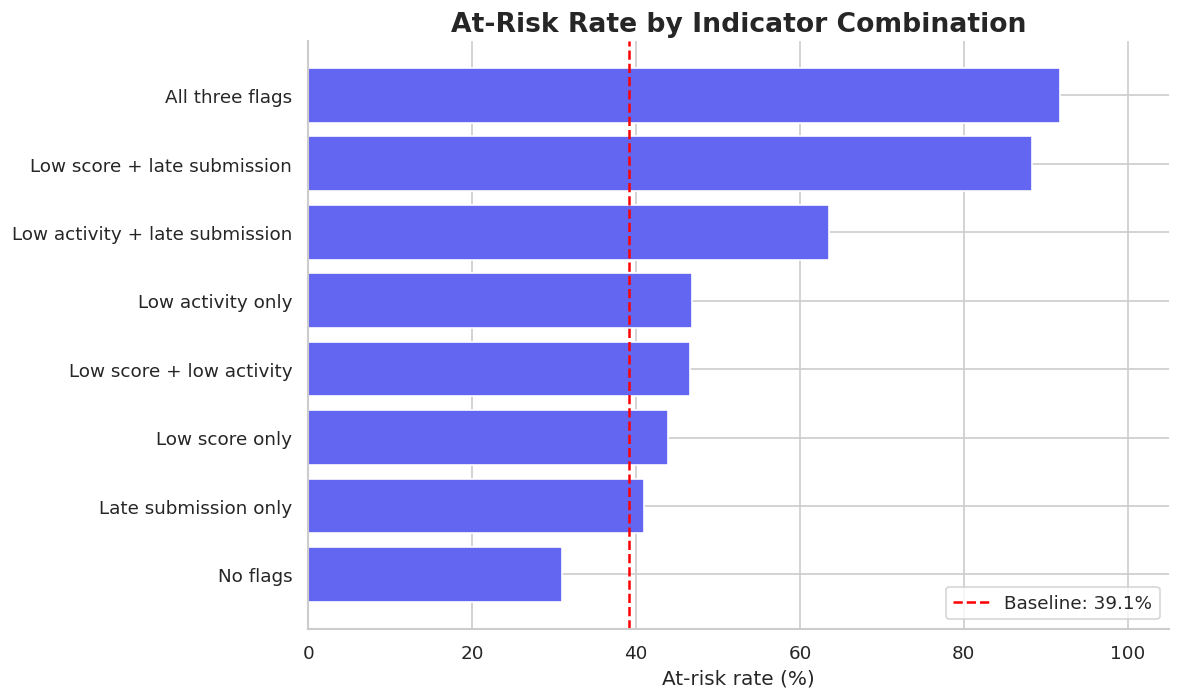

Results saved to: /kaggle/working/outputs/indicator_combinations


In [54]:
plot_data = ranked.sort_values("at_risk_rate")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data.index,
    plot_data["at_risk_rate"] * 100,
    color="#6366F1"
)

ax.axvline(
    baseline_rate * 100,
    color="red",
    linestyle="--",
    label=f"Baseline: {baseline_rate:.1%}"
)

ax.set_xlabel("At-risk rate (%)")
ax.set_ylabel("")
ax.set_title("At-Risk Rate by Indicator Combination")
ax.set_xlim(0, 105)
ax.legend()

plt.tight_layout()

fig.savefig(
    RESULTS_DIR / "segment_at_risk_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

segment_table.reset_index().to_csv(
    RESULTS_DIR / "segment_table.csv",
    index=False
)

coverage.to_csv(
    RESULTS_DIR / "analysis_coverage.csv",
    index=False
)

chi_results.to_csv(
    RESULTS_DIR / "chi_square_results.csv",
    index=False
)

(RESULTS_DIR / "findings.txt").write_text(
    findings,
    encoding="utf-8"
)

print("Results saved to:", RESULTS_DIR.resolve())

# **SCRUM-181: Engagement Clustering with K-Means**


In [55]:

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score



Define the cutoff and output directory

In [56]:

CUTOFF_DAY = 30
RANDOM_STATE = 42

KEY = [
    "code_module",
    "code_presentation",
    "id_student"
]

OUTPUT_DIR = Path("reports/scrum-181")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Day 30 cutoff:", CUTOFF_DAY)
print("Output directory:", OUTPUT_DIR)


Day 30 cutoff: 30
Output directory: reports/scrum-181


students active at Day 30
Reason: Students who registered after Day 30 or withdrew on or before Day 30 must not enter the clustering population. We retain the student identifier only as an internal join key; we do not display or save it in the outputs.

In [57]:

required_columns = KEY + [
    "date_registration",
    "date_unregistration"
]

missing_columns = [
    col for col in required_columns
    if col not in merged.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

population = merged[required_columns].copy()

population["date_registration"] = pd.to_numeric(
    population["date_registration"],
    errors="coerce"
)

population["date_unregistration"] = pd.to_numeric(
    population["date_unregistration"],
    errors="coerce"
)

eligible = (
    population["date_registration"].notna()
    & (population["date_registration"] <= CUTOFF_DAY)
    & (
        population["date_unregistration"].isna()
        | (population["date_unregistration"] > CUTOFF_DAY)
    )
)

population = population.loc[eligible].copy()

if population.duplicated(KEY).any():
    raise ValueError(
        "Duplicate student-module-presentation records found."
    )

print("Eligible student-course records:", len(population))
print(
    "Unique students in eligible population:",
    population["id_student"].nunique()
)
print(
    "Records with registration after Day 30:",
    int((population["date_registration"] > CUTOFF_DAY).sum())
)


Eligible student-course records: 27443
Unique students in eligible population: 24774
Records with registration after Day 30: 0


Calculate Day 30 engagement and inactivity

In [58]:

required_vle_columns = KEY + ["date", "sum_click"]

missing_columns = [
    col for col in required_vle_columns
    if col not in student_vle.columns
]

if missing_columns:
    raise ValueError(
        f"Missing VLE columns: {missing_columns}"
    )

vle_early = student_vle.loc[
    student_vle["date"].between(0, CUTOFF_DAY)
    & student_vle["sum_click"].gt(0),
    required_vle_columns
].copy()

activity_summary = (
    vle_early.groupby(KEY)
    .agg(
        engagement_days=("date", "nunique"),
        last_active_day=("date", "max"),
        total_clicks_day30=("sum_click", "sum")
    )
    .reset_index()
)

features = population.merge(
    activity_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

features["engagement_days"] = (
    features["engagement_days"].fillna(0)
)

features["total_clicks_day30"] = (
    features["total_clicks_day30"].fillna(0)
)

# Inactivity is the number of days since the last active day.
# A student with no recorded activity receives 31 days.
features["inactivity_days"] = (
    CUTOFF_DAY - features["last_active_day"]
)

features.loc[
    features["last_active_day"].isna(),
    "inactivity_days"
] = CUTOFF_DAY + 1

features["engagement_days"] = (
    features["engagement_days"].astype(int)
)

features["inactivity_days"] = (
    features["inactivity_days"].astype(int)
)

print("Engagement and inactivity features created.")
print("Population records:", len(features))
print(
    "Records with no recorded activity:",
    int((features["engagement_days"] == 0).sum())
)

display(
    features[
        ["engagement_days", "inactivity_days"]
    ].describe().round(2)
)


Engagement and inactivity features created.
Population records: 27443
Records with no recorded activity: 1121


,engagement_days,inactivity_days
count,27443.00,27443.00
mean,11.76,4.55
std,7.90,7.72
min,0.00,0.00
25%,5.00,0.00
50%,11.00,1.00
75%,17.00,5.00
max,31.00,31.00


Calculate score-so-far and handle missing scores
Some modules may not have assessments available by Day 30. Filling these missing scores with 77 would incorrectly suggest that those students achieved a score of 77.

In [59]:

required_assessment_columns = KEY + [
    "assessment_type",
    "date_submitted",
    "score",
    "is_banked"
]

missing_columns = [
    col for col in required_assessment_columns
    if col not in assessment_details.columns
]

if missing_columns:
    raise ValueError(
        f"Missing assessment columns: {missing_columns}"
    )

assessment_data = assessment_details.copy()

assessment_data["date_submitted"] = pd.to_numeric(
    assessment_data["date_submitted"],
    errors="coerce"
)

assessment_data["score"] = pd.to_numeric(
    assessment_data["score"],
    errors="coerce"
)

# Use only TMA/CMA submissions made by Day 30.
# Exclude banked assessments.
early_scores = assessment_data.loc[
    assessment_data["assessment_type"].isin(["TMA", "CMA"])
    & assessment_data["is_banked"].eq(0)
    & assessment_data["date_submitted"].between(
        0, CUTOFF_DAY
    )
].copy()

score_summary = (
    early_scores.groupby(KEY)
    .agg(
        score_so_far=("score", "mean"),
        assessments_scored=("score", "count")
    )
    .reset_index()
)

features = features.merge(
    score_summary,
    on=KEY,
    how="left",
    validate="one_to_one"
)

# Keep a separate indicator for missing early assessment scores.
features["no_assessment_yet"] = (
    features["score_so_far"].isna().astype(int)
)

no_assessment_count = int(
    features["no_assessment_yet"].sum()
)

# Use the observed median, not an arbitrary score such as 77.
observed_scores = features["score_so_far"].dropna()

if observed_scores.empty:
    raise ValueError(
        "No eligible Day 30 assessment scores are available. "
        "Review the assessment data before clustering."
    )

score_median = observed_scores.median()

features["score_so_far_imputed"] = (
    features["score_so_far"].fillna(score_median)
)

print("Assessment feature created.")
print("Records with no score available by the cutoff:",
      no_assessment_count)
print("Median of available scores:", round(score_median, 2))

display(
    features[
        ["score_so_far_imputed", "no_assessment_yet"]
    ].describe().round(2)
)


Assessment feature created.
Records with no score available by the cutoff: 7150
Median of available scores: 78.0


,score_so_far_imputed,no_assessment_yet
count,27443.00,27443.00
mean,74.61,0.26
std,18.60,0.44
min,0.00,0.00
25%,70.00,0.00
50%,78.00,0.00
75%,84.00,1.00
max,100.00,1.00


Prepare and scale the clustering features

In [60]:

FEATURE_COLUMNS = [
    "engagement_days",
    "inactivity_days",
    "score_so_far_imputed",
    "no_assessment_yet"
]

X = features[FEATURE_COLUMNS].copy()

if X.isna().any().any():
    raise ValueError(
        "Missing values remain in clustering features."
    )

if len(X) < 5:
    raise ValueError(
        "Not enough records to evaluate k starting at 4."
    )

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Number of feature columns:", len(FEATURE_COLUMNS))
print("Number of records:", X_scaled.shape[0])
print("Number of scaled features:", X_scaled.shape[1])
print("All scaled values finite:", np.isfinite(X_scaled).all())


Number of feature columns: 4
Number of records: 27443
Number of scaled features: 4
All scaled values finite: True


Evaluate k using the elbow and silhouette methods
We will begin at \(k=4\) and evaluate several candidate cluster counts. The final value should be justified by both the elbow curve and silhouette scores.

In [61]:

MIN_K = 4
MAX_K = min(10, len(X_scaled) - 1)

if MAX_K < MIN_K:
    raise ValueError(
        "Not enough records to evaluate k starting at 4."
    )

SILHOUETTE_SAMPLE_SIZE = min(5000, len(X_scaled))

evaluation_rows = []

for k in range(MIN_K, MAX_K + 1):
    candidate_model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    candidate_labels = candidate_model.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        candidate_labels,
        sample_size=SILHOUETTE_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )

    evaluation_rows.append({
        "k": k,
        "inertia": candidate_model.inertia_,
        "silhouette_score": silhouette
    })

k_results = pd.DataFrame(evaluation_rows)

display(
    k_results.round({
        "inertia": 2,
        "silhouette_score": 4
    })
)


,k,inertia,silhouette_score
0,4,38122.80,0.4322
1,5,26989.24,0.4046
2,6,22317.58,0.4017
3,7,19703.46,0.4019
4,8,17316.07,0.3852
5,9,15532.99,0.3761
6,10,14128.27,0.3837


Plot the evaluation metrics

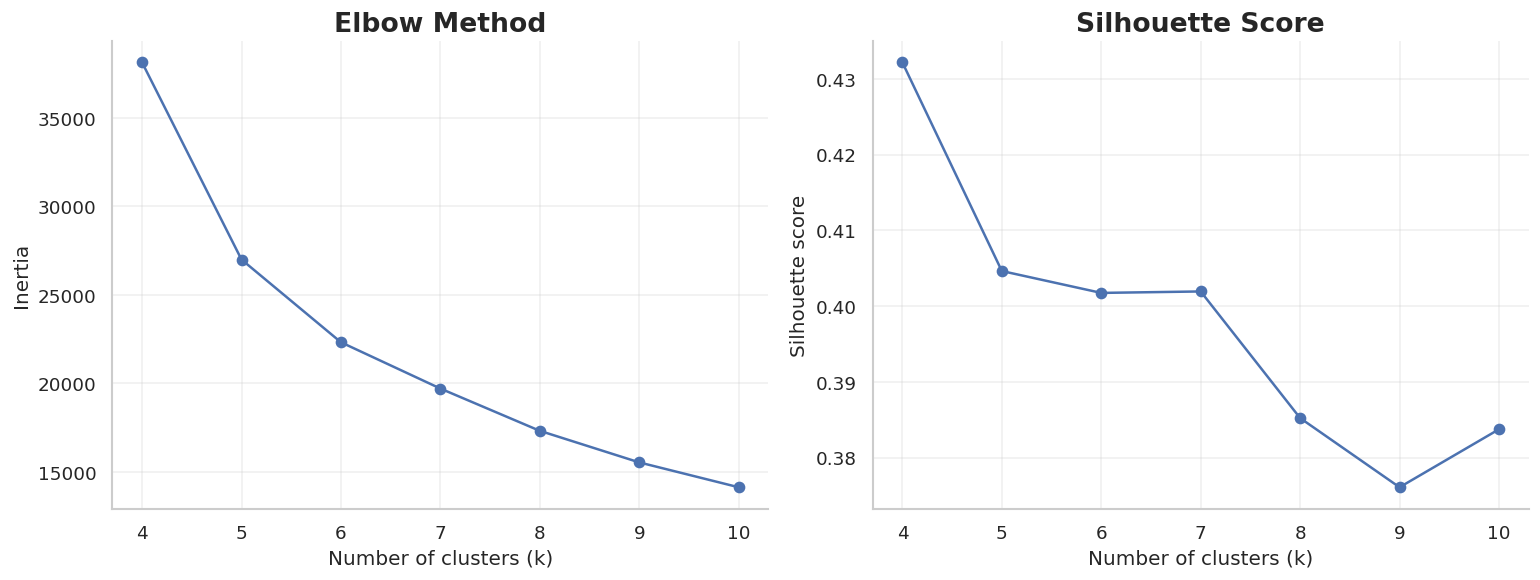

In [62]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    k_results["k"],
    k_results["inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_results["k"])
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    k_results["k"],
    k_results["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(k_results["k"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Select k and fit the final model
The following code selects the candidate with the highest measured silhouette score as a starting recommendation

In [63]:

best_row = k_results.loc[
    k_results["silhouette_score"].idxmax()
]

BEST_K = int(best_row["k"])

final_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=20
)

cluster_labels = final_model.fit_predict(X_scaled)

print("Selected k:", BEST_K)
print(
    "Selected silhouette score:",
    round(float(best_row["silhouette_score"]), 4)
)
print(
    "Selected model inertia:",
    round(float(final_model.inertia_), 2)
)


Selected k: 4
Selected silhouette score: 0.4322
Selected model inertia: 38122.8


The silhouette score was highest at (k=4), approximately 0.432, indicating better cluster separation compared with the other tested values. The inertia curve shows a sharp decrease at lower values of (k), with a possible elbow around (k=6).

Although the elbow plot suggests that (k=6) may also be reasonable, (k=4) was selected because it achieved the highest silhouette score and provides a simpler clustering solution. The final cluster sizes and student characteristics should be reviewed to ensure that the resulting groups are meaningful.

Report cluster sizes

In [64]:

cluster_sizes = (
    pd.Series(cluster_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="student_course_records")
)

cluster_sizes["percentage"] = (
    cluster_sizes["student_course_records"]
    / len(cluster_labels) * 100
).round(2)

assert int(cluster_sizes["student_course_records"].sum()) == len(features)

print("Total eligible student-course records:", len(features))
print("Number of clusters:", len(cluster_sizes))

display(cluster_sizes)


Total eligible student-course records: 27443
Number of clusters: 4


,cluster,student_course_records,percentage
0,0,5196,18.93
1,1,4971,18.11
2,2,2428,8.85
3,3,14848,54.10


Save the model and evaluation results

In [65]:

# Save the fitted model and preprocessing information.
MODEL_PATH = OUTPUT_DIR / "day30_kmeans.joblib"

joblib.dump(
    {
        "model": final_model,
        "scaler": scaler,
        "feature_columns": FEATURE_COLUMNS,
        "score_median": float(score_median),
        "cutoff_day": CUTOFF_DAY,
        "selected_k": BEST_K,
        "random_state": RANDOM_STATE
    },
    MODEL_PATH
)

# Save candidate-k evaluation metrics.
METRICS_PATH = OUTPUT_DIR / "k_selection_metrics.csv"
k_results.to_csv(METRICS_PATH, index=False)

# Save aggregated cluster sizes only.
CLUSTER_SIZES_PATH = OUTPUT_DIR / "cluster_sizes.csv"
cluster_sizes.to_csv(CLUSTER_SIZES_PATH, index=False)

# Save a short explanation of the selection.
JUSTIFICATION_PATH = OUTPUT_DIR / "k_selection_justification.txt"

justification = (
    f"Day 30 K-Means clustering\n"
    f"Selected k: {BEST_K}\n"
    f"Selection rule: highest sampled silhouette score "
    f"among candidate k values from {MIN_K} to {MAX_K}.\n"
    f"Selected silhouette score: "
    f"{float(best_row['silhouette_score']):.4f}\n"
    f"Inertia: {float(best_row['inertia']):.2f}\n"
    f"Silhouette sample size: {SILHOUETTE_SAMPLE_SIZE}\n"
    f"Population records: {len(features)}\n"
    f"Elbow curve must also be reviewed and its interpretation "
    f"documented before final approval.\n"
)

JUSTIFICATION_PATH.write_text(
    justification,
    encoding="utf-8"
)

print("Model saved:", MODEL_PATH)
print("Evaluation metrics saved:", METRICS_PATH)
print("Cluster sizes saved:", CLUSTER_SIZES_PATH)
print("Selection justification saved:", JUSTIFICATION_PATH)


Model saved: reports/scrum-181/day30_kmeans.joblib
Evaluation metrics saved: reports/scrum-181/k_selection_metrics.csv
Cluster sizes saved: reports/scrum-181/cluster_sizes.csv
Selection justification saved: reports/scrum-181/k_selection_justification.txt


In [66]:

# Verify that the model can be loaded again.
saved_artifact = joblib.load(MODEL_PATH)

loaded_model = saved_artifact["model"]
loaded_scaler = saved_artifact["scaler"]

# Confirm the loaded model produces the same assignments.
reloaded_labels = loaded_model.predict(
    loaded_scaler.transform(X)
)

assert np.array_equal(cluster_labels, reloaded_labels)

# Verify the exported tables contain no student identifier.
saved_metrics = pd.read_csv(METRICS_PATH)
saved_sizes = pd.read_csv(CLUSTER_SIZES_PATH)

assert "id_student" not in saved_metrics.columns
assert "id_student" not in saved_sizes.columns

assert int(saved_sizes["student_course_records"].sum()) == len(features)
assert saved_artifact["selected_k"] == BEST_K

print("Model reload test: PASSED")
print("Cluster assignment reproducibility test: PASSED")
print("Student ID privacy checks: PASSED")
print("Cluster-size total validation: PASSED")
print("Selected k:", BEST_K)
print("All SCRUM-181 output checks completed.")


Model reload test: PASSED
Cluster assignment reproducibility test: PASSED
Student ID privacy checks: PASSED
Cluster-size total validation: PASSED
Selected k: 4
All SCRUM-181 output checks completed.


In [67]:
import numpy as np
import pandas as pd

# 1. Keep the clustering features and cluster assignments.

In [68]:
profile_data = features[KEY + FEATURE_COLUMNS].copy()
profile_data["cluster"] = cluster_labels

In [69]:
# 2. Attach final outcomes for evaluation.
# Final outcomes are not used to create the K-Means clusters.
outcomes = (
    merged[KEY + ["final_result"]]
    .drop_duplicates(subset=KEY)
)

profile_data = profile_data.merge(
    outcomes,
    on=KEY,
    how="left",
    validate="one_to_one"
)

if profile_data["final_result"].isna().any():
    raise ValueError(
        "Some records do not have a final outcome. Check the merge."
    )


In [70]:
# 3. Define At Risk as Fail or Withdrawn.
profile_data["at_risk"] = (
    profile_data["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)

In [71]:
# 4. Calculate the centroid of each cluster.
# These are average values in the original feature units.
centroids = (
    profile_data
    .groupby("cluster")[FEATURE_COLUMNS]
    .mean()
    .round(2)
)

In [72]:
# 5. Calculate each cluster's size and At Risk rate.
risk_summary = (
    profile_data
    .groupby("cluster")
    .agg(
        records=("at_risk", "size"),
        at_risk_records=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

risk_summary["at_risk_rate_pct"] = (
    risk_summary["at_risk_rate"] * 100
).round(2)

In [73]:
# 6. Calculate the overall At Risk rate for comparison.
overall_at_risk_rate = (
    profile_data["at_risk"].mean() * 100
)


In [74]:
# 7. Display only aggregated results, never student IDs.
print("CENTROID SUMMARY")
display(centroids)

print("CLUSTER SIZE AND AT RISK SUMMARY")
display(
    risk_summary[
        [
            "cluster",
            "records",
            "at_risk_records",
            "at_risk_rate_pct"
        ]
    ]
)

print(
    f"Overall Day 30 At Risk rate: "
    f"{overall_at_risk_rate:.2f}%"
)


CENTROID SUMMARY


,engagement_days,inactivity_days,score_so_far_imputed,no_assessment_yet
cluster,,,,
0,8.42,4.20,46.70,0.0
1,8.70,3.46,78.00,1.0
2,1.13,25.86,77.71,0.9
3,15.69,1.56,82.74,0.0


CLUSTER SIZE AND AT RISK SUMMARY


,cluster,records,at_risk_records,at_risk_rate_pct
0,0,5196,3260,62.74
1,1,4971,2419,48.66
2,2,2428,1826,75.21
3,3,14848,4560,30.71


Overall Day 30 At Risk rate: 43.96%


In [75]:
# 8. Validate the summary.
assert len(profile_data) == len(features)
assert risk_summary["records"].sum() == len(features)
assert risk_summary["at_risk_rate"].between(0, 1).all()

print("Cell 1 validation: PASSED")

Cell 1 validation: PASSED


profile comparison statistics

In [76]:
import pandas as pd
import numpy as np


In [77]:
# 1. Check that the required variables exist.
required_variables = [
    "features",
    "cluster_labels",
    "FEATURE_COLUMNS",
    "KEY",
    "merged"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Run the earlier clustering cells first. Missing: "
        f"{missing_variables}"
    )

In [82]:
# SCRUM-183 — Cell 4: Map clusters to profiles

cluster_to_profile = {
    0: "Struggling Silently",
    1: "Improving",
    2: "Disengaged",
    3: "On Track"
}

profile_data["profile"] = profile_data["cluster"].map(
    cluster_to_profile
)

# Check that every cluster received a profile
assert profile_data["profile"].notna().all()

# Compare profiles against At Risk outcomes
profile_summary = (
    profile_data.groupby("profile")
    .agg(
        records=("at_risk", "size"),
        at_risk_records=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean"),
        engagement_days=("engagement_days", "mean"),
        inactivity_days=("inactivity_days", "mean"),
        average_score=("score_so_far_imputed", "mean")
    )
    .reset_index()
)

profile_summary["at_risk_rate_pct"] = (
    profile_summary["at_risk_rate"] * 100
).round(2)

display(profile_summary.round(2))

,profile,records,at_risk_records,at_risk_rate,engagement_days,inactivity_days,average_score,at_risk_rate_pct
0,Disengaged,2428,1826,0.75,1.13,25.86,77.71,75.21
1,Improving,4971,2419,0.49,8.70,3.46,78.00,48.66
2,On Track,14848,4560,0.31,15.69,1.56,82.74,30.71
3,Struggling Silently,5196,3260,0.63,8.42,4.20,46.70,62.74



# **Profile comparison charts**


In [79]:
print("features:", "features" in globals())
print("cluster_labels:", "cluster_labels" in globals())
print("cluster_centers:", "final_model" in globals())
print("merged:", "merged" in globals())
print("profile_data:", "profile_data" in globals())
print("cluster_summary:", "cluster_summary" in globals())

features: True
cluster_labels: True
cluster_centers: True
merged: True
profile_data: True
cluster_summary: False


In [81]:
# SCRUM-183 — Cell 3: Inspect cluster centroids

centroid_values = scaler.inverse_transform(
    final_model.cluster_centers_
)

centroid_summary = pd.DataFrame(
    centroid_values,
    columns=FEATURE_COLUMNS
)

centroid_summary.insert(
    0,
    "cluster",
    range(len(centroid_summary))
)

display(centroid_summary.round(2))

,cluster,engagement_days,inactivity_days,score_so_far_imputed,no_assessment_yet
0,0,8.43,4.20,46.68,0.0
1,1,8.70,3.46,78.00,1.0
2,2,1.13,25.86,77.71,0.9
3,3,15.68,1.56,82.75,0.0


 **Calculate cluster summaries**

In [80]:
# SCRUM-183 — Cell 2: Calculate cluster summaries

# Check that the required columns are available
required_columns = KEY + FEATURE_COLUMNS + ["cluster"]

missing_columns = [
    col for col in required_columns
    if col not in profile_data.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Attach final outcomes if they are not already present
if "final_result" not in profile_data.columns:
    outcomes = (
        merged[KEY + ["final_result"]]
        .drop_duplicates(subset=KEY)
    )

    profile_data = profile_data.merge(
        outcomes,
        on=KEY,
        how="left",
        validate="one_to_one"
    )

# Check that outcomes are available
if profile_data["final_result"].isna().any():
    raise ValueError(
        "Some final outcomes are missing. Check the merge."
    )

# At Risk = Fail or Withdrawn
profile_data["at_risk"] = (
    profile_data["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)

# Summarise each cluster
cluster_summary = (
    profile_data.groupby("cluster")
    .agg(
        records=("at_risk", "size"),
        engagement_days=("engagement_days", "mean"),
        inactivity_days=("inactivity_days", "mean"),
        average_score=("score_so_far_imputed", "mean"),
        no_assessment_rate=("no_assessment_yet", "mean"),
        at_risk_records=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

# Convert rates to percentages
cluster_summary["no_assessment_rate_pct"] = (
    cluster_summary["no_assessment_rate"] * 100
).round(2)

cluster_summary["at_risk_rate_pct"] = (
    cluster_summary["at_risk_rate"] * 100
).round(2)

# Round average values
numeric_columns = [
    "engagement_days",
    "inactivity_days",
    "average_score"
]

cluster_summary[numeric_columns] = (
    cluster_summary[numeric_columns].round(2)
)

# Display aggregate results
display(
    cluster_summary[
        [
            "cluster",
            "records",
            "engagement_days",
            "inactivity_days",
            "average_score",
            "no_assessment_rate_pct",
            "at_risk_records",
            "at_risk_rate_pct"
        ]
    ]
)

print("Cluster summary created successfully.")
print(
    "Overall At Risk rate:",
    round(profile_data["at_risk"].mean() * 100, 2),
    "%"
)

,cluster,records,engagement_days,inactivity_days,average_score,no_assessment_rate_pct,at_risk_records,at_risk_rate_pct
0,0,5196,8.42,4.20,46.70,0.00,3260,62.74
1,1,4971,8.70,3.46,78.00,100.00,2419,48.66
2,2,2428,1.13,25.86,77.71,89.74,1826,75.21
3,3,14848,15.69,1.56,82.74,0.00,4560,30.71


Cluster summary created successfully.
Overall At Risk rate: 43.96 %


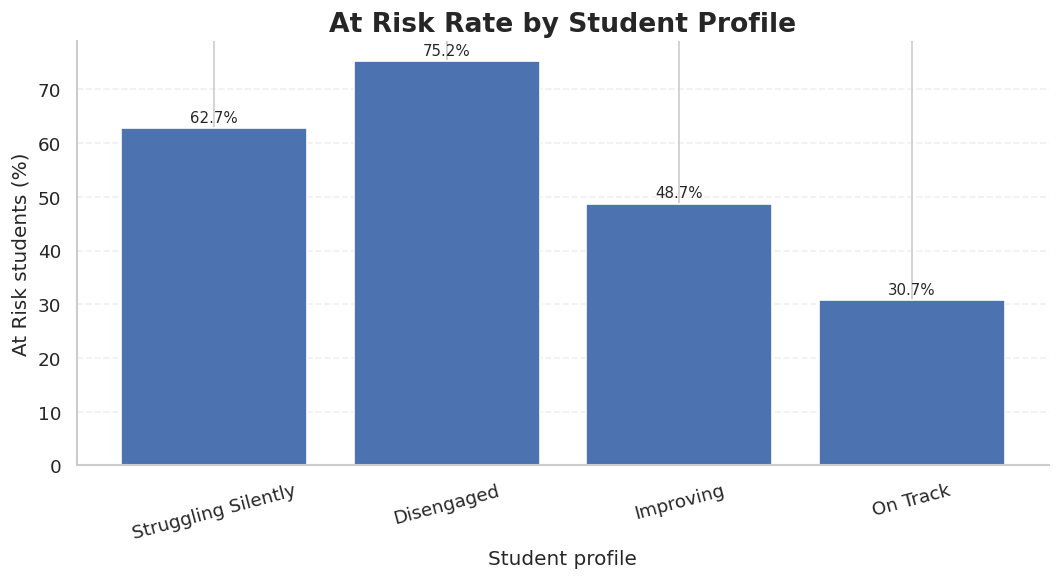

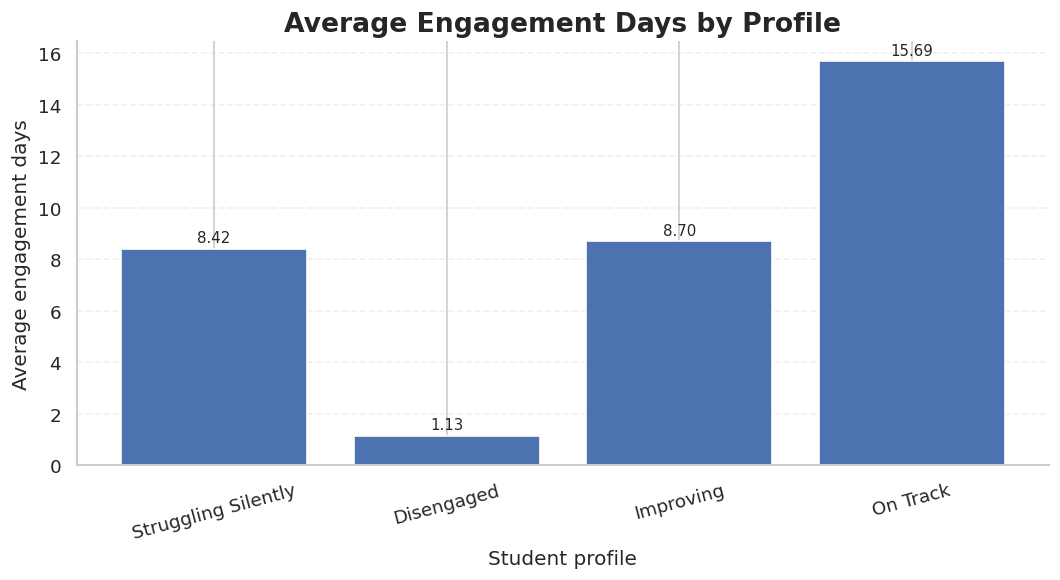

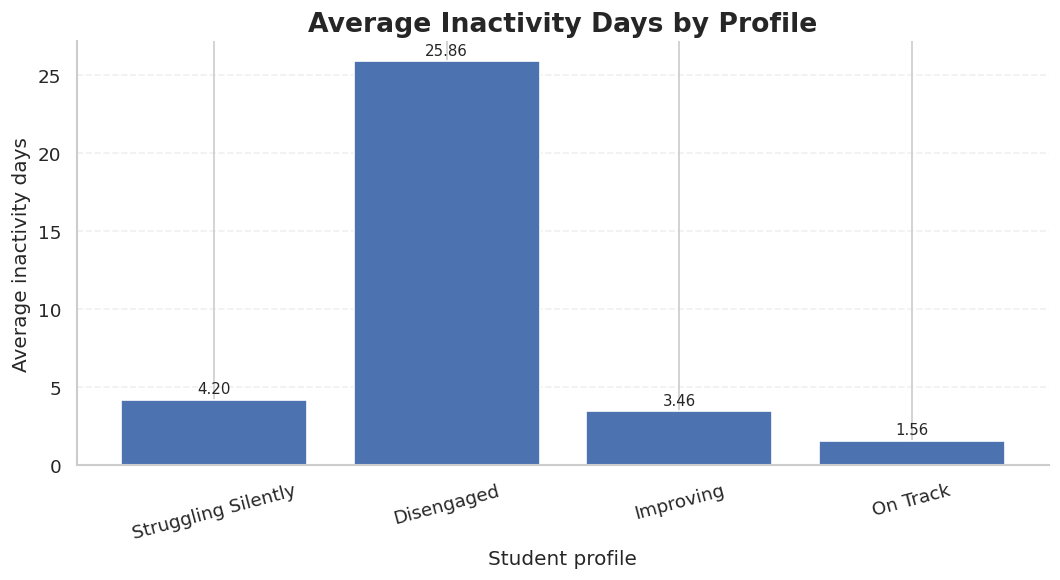

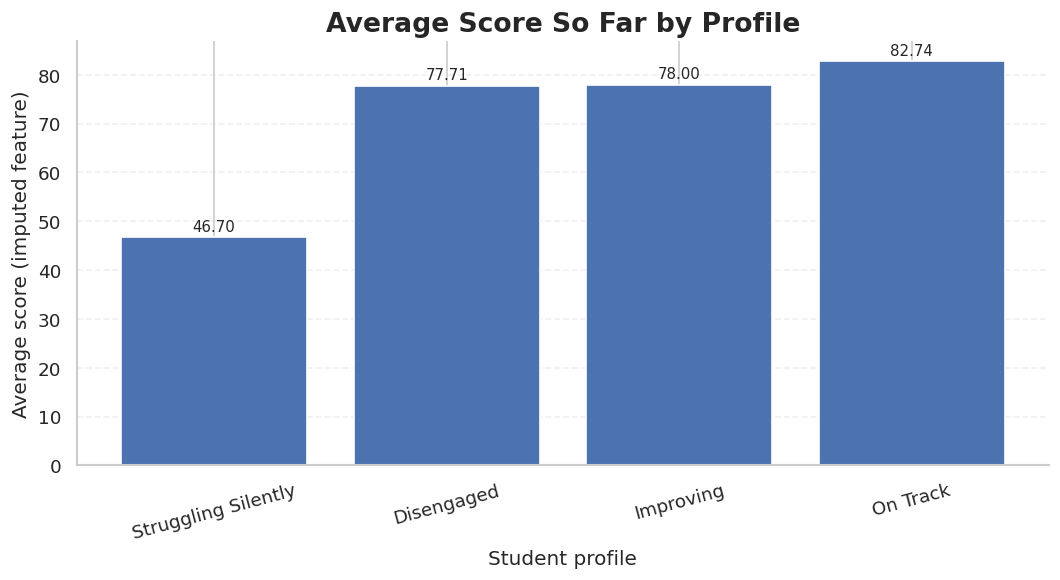

,profile,records,at_risk_records,at_risk_rate_pct,engagement_days,inactivity_days,average_score
0,Struggling Silently,5196,3260,62.74,8.42,4.20,46.70
1,Disengaged,2428,1826,75.21,1.13,25.86,77.71
2,Improving,4971,2419,48.66,8.70,3.46,78.00
3,On Track,14848,4560,30.71,15.69,1.56,82.74



Saved files:
- data/processed/profile_at_risk_rate.png
- data/processed/profile_engagement_days.png
- data/processed/profile_inactivity_days.png
- data/processed/profile_average_score.png
- data/processed/profile_comparison_summary.csv


In [83]:

# SCRUM-183 — Cell 5: Profile comparison charts

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# 1. Check that profile mapping is complete
required_columns = [
    "profile",
    "at_risk",
    "engagement_days",
    "inactivity_days",
    "score_so_far_imputed"
]

missing = [
    col for col in required_columns
    if col not in profile_data.columns
]

if missing:
    raise ValueError(
        f"Missing columns in profile_data: {missing}. "
        "Run the profile mapping cell first."
    )

if profile_data["profile"].isna().any():
    raise ValueError("Some records do not have a profile label.")

# 2. Create output folder
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 3. Calculate profile comparison statistics
profile_summary = (
    profile_data.groupby("profile")
    .agg(
        records=("at_risk", "size"),
        at_risk_records=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean"),
        engagement_days=("engagement_days", "mean"),
        inactivity_days=("inactivity_days", "mean"),
        average_score=("score_so_far_imputed", "mean")
    )
    .reset_index()
)

profile_summary["at_risk_rate_pct"] = (
    profile_summary["at_risk_rate"] * 100
)

# Display profiles in a meaningful order
profile_order = [
    "Struggling Silently",
    "Disengaged",
    "Improving",
    "On Track"
]

profile_summary["profile"] = pd.Categorical(
    profile_summary["profile"],
    categories=profile_order,
    ordered=True
)

profile_summary = (
    profile_summary.sort_values("profile").reset_index(drop=True)
)

# Save the aggregate summary for review
summary_path = output_dir / "profile_comparison_summary.csv"
profile_summary.to_csv(summary_path, index=False)

# Use the same profile order in every chart
labels = profile_summary["profile"].astype(str).tolist()

def save_bar_chart(values, title, ylabel, filename,
                   color=None, percentage=False):
    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(labels, values, color=color)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Student profile")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # Add value labels to each bar
    for bar, value in zip(bars, values):
        label = f"{value:.1f}%" if percentage else f"{value:.2f}"
        ax.annotate(
            label,
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Chart 1: At Risk rate
save_bar_chart(
    profile_summary["at_risk_rate_pct"],
    "At Risk Rate by Student Profile",
    "At Risk students (%)",
    "profile_at_risk_rate.png",
    percentage=True
)

# Chart 2: Average engagement days
save_bar_chart(
    profile_summary["engagement_days"],
    "Average Engagement Days by Profile",
    "Average engagement days",
    "profile_engagement_days.png"
)

# Chart 3: Average inactivity days
save_bar_chart(
    profile_summary["inactivity_days"],
    "Average Inactivity Days by Profile",
    "Average inactivity days",
    "profile_inactivity_days.png"
)

# Chart 4: Average score so far
save_bar_chart(
    profile_summary["average_score"],
    "Average Score So Far by Profile",
    "Average score (imputed feature)",
    "profile_average_score.png"
)

# 4. Show aggregate comparison table
display(
    profile_summary[
        [
            "profile",
            "records",
            "at_risk_records",
            "at_risk_rate_pct",
            "engagement_days",
            "inactivity_days",
            "average_score"
        ]
    ].round(2)
)

print("\nSaved files:")
print(f"- {output_dir / 'profile_at_risk_rate.png'}")
print(f"- {output_dir / 'profile_engagement_days.png'}")
print(f"- {output_dir / 'profile_inactivity_days.png'}")
print(f"- {output_dir / 'profile_average_score.png'}")
print(f"- {summary_path}")
